# Stima dei prezzi residenziali: confronto tra modelli regolarizzati

**RealEstateAI Solutions – Team Data Science**

## Il problema
Il motore di valutazione attuale si basa su una regressione lineare multipla. In addestramento
funziona bene, ma sugli immobili nuovi le stime si discostano più del previsto: il sospetto è
l'**overfitting**, cioè un modello che si adatta troppo ai dati visti e generalizza male.

## La domanda
La **regolarizzazione** (Ridge, Lasso, Elastic Net) migliora le stime? Quali caratteristiche
dell'immobile pesano davvero sul prezzo? Il modello sbaglia sistematicamente su qualche fascia di prezzo?

## Come leggere questo notebook
Ogni blocco di codice è preceduto da una spiegazione (*cosa facciamo e perché*) e seguito da un
commento (*cosa osserviamo*). Chi non scrive codice può leggere solo le parti di testo.

## Indice
1. Librerie e impostazioni
2. Funzioni di supporto
3. Lettura e pulizia del dataset
4. Analisi esplorativa
5. Split train/test e modello di riferimento (baseline)
6. Modelli regolarizzati con due codifiche di `furnishingstatus`
7. Confronto tra codifiche e modelli (prezzo originale)
8. Passaggio al logaritmo del prezzo
9. Prezzo originale vs logaritmo e scelta del modello finale
10. Valutazione finale sul test set
11. Conclusioni e raccomandazione

## 1. Librerie e impostazioni
Importiamo tutte le librerie usate nel notebook e fissiamo le costanti del progetto, in
particolare il seme casuale `RANDOM_STATE` che rende i risultati riproducibili.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import (GridSearchCV, KFold, RepeatedKFold, cross_val_predict,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Riproducibilità
RANDOM_STATE = 42

# Dati
DATA_URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/housing.csv"
TARGET = "price"
NUMERIC_COLS = ["area", "bedrooms", "bathrooms", "stories", "parking"]
BINARY_COLS = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
FURNISH_COL = "furnishingstatus"
FEATURE_COLS = NUMERIC_COLS + BINARY_COLS + [FURNISH_COL]

# furnishingstatus: significato dei codici nel CSV e ricodifica nell'ordine corretto
FURNISH_ETICHETTE = {0: "non arredato", 1: "arredato", 2: "semi-arredato"}
FURNISH_CORRETTO = {0: 0, 1: 2, 2: 1}  # codice CSV -> 0 non arredato, 1 semi, 2 arredato

# Esperimenti
ENCODINGS = ["ordinal_corretto", "onehot"]
NOMI_MODELLI = ["Lineare", "Ridge", "Lasso", "ElasticNet"]
TARGETS = ["prezzo", "log(prezzo)"]

# Stile dei grafici
sns.set_theme(style="whitegrid", context="notebook")
COLORI_MODELLI = dict(zip(NOMI_MODELLI, sns.color_palette("colorblind", len(NOMI_MODELLI))))
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. Funzioni di supporto
Raccogliamo qui tutte le funzioni usate nel resto del notebook. Usare **le stesse funzioni per
ogni esperimento** garantisce che tutti i modelli siano preparati e valutati con lo stesso
protocollo: le differenze nei risultati dipendono dai modelli, non da dettagli di codice.

### 2a. Preparazione dei dati
- **Due codifiche** di `furnishingstatus` (l'unica categorica con 3 livelli; le altre sono già 0/1):
  - `ordinal_corretto`: ricodifica nell'ordine naturale 0 non arredato → 1 semi → 2 arredato;
  - `onehot`: una colonna 0/1 per "arredato" e una per "semi-arredato", con "non arredato" come riferimento.
- **Standardizzazione** di tutte le feature (media 0, deviazione standard 1): la penalità della
  regolarizzazione dipende dalla scala delle variabili, quindi le mettiamo tutte sullo stesso metro.
- Tutto dentro una **Pipeline**: in cross-validation la standardizzazione viene calcolata solo sui
  dati di training di ciascun fold, evitando che informazioni della validazione "trapelino" nel modello.

In [2]:
def crea_modello(nome):
    """Crea un modello nuovo, non ancora addestrato, a partire dal suo nome.

    Serve per avere sempre un'istanza "pulita": ogni esperimento parte da zero e non eredita
    nulla da addestramenti precedenti.

    nome: "Lineare", "Ridge", "Lasso" o "ElasticNet".
    Restituisce il modello di scikit-learn corrispondente. Per Lasso ed Elastic Net alziamo il
    numero massimo di iterazioni (max_iter), così l'algoritmo ha il tempo di arrivare alla soluzione.
    """
    if nome == "Lineare":
        return LinearRegression()
    if nome == "Ridge":
        return Ridge()
    if nome == "Lasso":
        return Lasso(max_iter=100_000)
    if nome == "ElasticNet":
        return ElasticNet(max_iter=100_000)
    raise ValueError(f"Modello sconosciuto: {nome}")


def _ricodifica_arredamento(X):
    """Riordina i codici di furnishingstatus nell'ordine naturale dei livelli.

    Nel CSV i codici sono 0 = non arredato, 1 = arredato, 2 = semi-arredato (sezione 3): usati così,
    "semi-arredato" risulterebbe *oltre* "arredato". Questa funzione li trasforma in
    0 = non arredato, 1 = semi-arredato, 2 = arredato, usando la mappa FURNISH_CORRETTO.

    X: tabella (DataFrame) con la colonna furnishingstatus.
    Restituisce una copia di X con la colonna ricodificata; la tabella originale non viene toccata.
    """
    X = X.copy()
    X[FURNISH_COL] = X[FURNISH_COL].map(FURNISH_CORRETTO)
    return X


def costruisci_preprocessore(encoding):
    """Prepara le 12 feature prima del modello, scegliendo come codificare furnishingstatus.

    Le 5 numeriche e le 6 binarie passano invariate ("passthrough"); cambia solo furnishingstatus:
    - "ordinal_corretto": codici riordinati con _ricodifica_arredamento (0 non arredato, 1 semi,
      2 arredato);
    - "onehot": due colonne 0/1, "arredato" e "semi-arredato"; "non arredato" è il riferimento
      (tutte e due a 0), per questo la sua colonna viene eliminata (drop="first").

    Il ColumnTransformer applica a ogni gruppo di colonne la sua trasformazione e rimette insieme i
    risultati; con set_output(transform="pandas") il risultato è un DataFrame con i nomi delle
    colonne, utile per leggere i coefficienti.

    encoding: "ordinal_corretto" o "onehot".
    Restituisce il preprocessore, non ancora addestrato.
    """
    if encoding == "ordinal_corretto":
        trasformazione_arredo = FunctionTransformer(_ricodifica_arredamento, feature_names_out="one-to-one")
    elif encoding == "onehot":
        trasformazione_arredo = OneHotEncoder(categories=[[0, 1, 2]], drop="first", sparse_output=False)
    else:
        raise ValueError(f"Codifica sconosciuta: {encoding}")
    preprocessore = ColumnTransformer(
        [("numeriche", "passthrough", NUMERIC_COLS),
         ("binarie", "passthrough", BINARY_COLS),
         ("arredamento", trasformazione_arredo, [FURNISH_COL])],
        verbose_feature_names_out=False,
    )
    return preprocessore.set_output(transform="pandas")


def costruisci_pipeline(encoding, nome_modello, log_target=False):
    """Mette in fila, in un unico oggetto, tutti i passi dai dati grezzi alla previsione.

    I passi sono: codifica delle feature (costruisci_preprocessore) ->
    standardizzazione (ogni colonna con media 0 e deviazione standard 1) -> modello. Avere tutto in una Pipeline fa sì che,
    in cross-validation, la standardizzazione venga calcolata solo sui dati di addestramento di
    ogni fold: la validazione resta davvero "mai vista".

    encoding: codifica di furnishingstatus (vedi costruisci_preprocessore).
    nome_modello: "Lineare", "Ridge", "Lasso" o "ElasticNet".
    log_target: se True il modello impara log(prezzo) invece del prezzo. Il TransformedTargetRegressor
        applica il logaritmo al prezzo durante l'addestramento e l'esponenziale alle previsioni, così
        predict() restituisce comunque prezzi.
    Restituisce la pipeline (o la pipeline avvolta nel TransformedTargetRegressor), non addestrata.
    """
    pipeline = Pipeline([("prep", costruisci_preprocessore(encoding)), ("scaler", StandardScaler()),
                         ("model", crea_modello(nome_modello))])
    if log_target:
        return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp,
                                          check_inverse=False)
    return pipeline


def pipeline_interna(estimatore):
    """Restituisce la Pipeline addestrata, anche quando è avvolta in un TransformedTargetRegressor.

    Con log_target=True la pipeline si trova un livello più in basso, in `regressor_` (il trattino
    basso finale indica, in scikit-learn, la copia addestrata durante il fit). Questa funzione
    permette di leggere coefficienti e scaler allo stesso modo per entrambi i target.

    estimatore: una Pipeline addestrata o un TransformedTargetRegressor addestrato.
    """
    return estimatore.regressor_ if isinstance(estimatore, TransformedTargetRegressor) else estimatore

### 2b. Addestramento e valutazione
- **Split stratificato**: mettiamo da parte il 20% dei dati come *test set*, mantenendo in entrambe
  le parti la stessa proporzione di case economiche, medie e costose (5 fasce di prezzo).
- **Cross-validation ripetuta** (5 fold × 3 ripetizioni = 15 valutazioni): ogni configurazione viene
  addestrata e valutata 15 volte su porzioni diverse del training set; riportiamo media e deviazione
  standard dell'errore. Il CSV è ordinato per prezzo, quindi i dati vengono **mescolati** prima di dividerli.
- **Ricerca degli iperparametri**: per ogni modello proviamo molti valori della forza di regolarizzazione
  `alpha` (e, per Elastic Net, del mix `l1_ratio` tra Lasso e Ridge) e teniamo il migliore.
- **Metriche**: MSE (errore quadratico medio), RMSE (radice dell'MSE, nell'unità del prezzo: "errore
  tipico"), MAE (errore assoluto medio, nell'unità del prezzo), R² (quota di variabilità del prezzo
  spiegata dal modello).
- **Scelta del modello**: vince la configurazione con l'**RMSE medio di cross-validation più basso**.
  Accanto riportiamo sempre la deviazione standard tra i fold, per capire se una differenza è grande o
  piccola rispetto alla variabilità dovuta alla scelta dei fold.


- **Effetti reali**: i coefficienti di un modello addestrato su feature standardizzate indicano l'effetto
  di "+1 deviazione standard". Dividendo per la deviazione standard otteniamo l'effetto per unità reale
  (una camera in più, avere l'aria condizionata, un'unità di area in più), espresso nell'unità del prezzo.

In [3]:
# Valori di alpha (forza della regolarizzazione) da provare, per modello e target (True = log(prezzo)).
# np.logspace(a, b, n) genera n valori da 10^a a 10^b, ognuno uguale al precedente moltiplicato per lo
# stesso fattore (es. logspace(0, 3, 4) = 1, 10, 100, 1000). Per alpha conta l'ordine di grandezza, non
# il valore preciso: passare da 0,01 a 0,1 cambia il modello quanto passare da 100 a 1000.
# Gli estremi vanno da "penalità praticamente nulla" (= regressione lineare) a "penalità che azzera
# tutti i coefficienti", così l'alpha migliore cade dentro la griglia:
# - Ridge riduce ogni coefficiente di circa n / (n + alpha), con n ≈ 350 case per fold: alpha = 0,001
#   non cambia nulla, alpha = 10^4 schiaccia quasi tutto. Il fattore non dipende dall'unità del target,
#   quindi la stessa griglia va bene per prezzo e log(prezzo);
# - Lasso ed Elastic Net sottraggono alpha direttamente ai coefficienti, che sono espressi nell'unità del
#   target: sul prezzo valgono centinaia di migliaia (da 10^0 a 10^6), sul log(prezzo) qualche decimo
#   (da 10^-5 a 10^0).
# 30 punti (circa 4-5 per ordine di grandezza) bastano, perché l'errore varia in modo regolare con alpha.
# Elastic Net ne ha 20 perché ogni alpha va provato con 7 valori di l1_ratio (140 combinazioni invece di
# 210). Se l'alpha migliore cade sull'estremo superiore, alpha_al_bordo lo segnala: griglia da allargare.
GRIGLIE_ALPHA = {
    ("Ridge", False): np.logspace(-3, 4, 30),
    ("Ridge", True): np.logspace(-3, 4, 30),
    ("Lasso", False): np.logspace(0, 6, 30),
    ("Lasso", True): np.logspace(-5, 0, 30),
    ("ElasticNet", False): np.logspace(0, 6, 20),
    ("ElasticNet", True): np.logspace(-5, 0, 20),
}

# Mix tra le due penalità di Elastic Net: vicino a 0 si comporta come Ridge, vicino a 1 come Lasso
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

# Metriche calcolate in cross-validation. scikit-learn massimizza sempre il punteggio, quindi gli errori
# sono restituiti con il segno meno ("neg_..."): li rigiriamo in addestra_configurazione
SCORING = {"mse": "neg_mean_squared_error", "rmse": "neg_root_mean_squared_error",
           "mae": "neg_mean_absolute_error", "r2": "r2"}

# Unità reale di ciascuna feature numerica, usata nella tabella degli effetti
UNITA_FEATURE = {"area": "per unità di area", "bedrooms": "per camera in più", "bathrooms": "per bagno in più",
                 "stories": "per piano in più", "parking": "per posto auto in più",
                 "furnishingstatus": "per livello di arredamento"}

# Nomi leggibili per le colonne create dal one-hot
NOMI_LEGGIBILI = {"furnishingstatus_1": "arredamento: arredato (vs non arredato)",
                  "furnishingstatus_2": "arredamento: semi-arredato (vs non arredato)"}


def split_stratificato(df, test_size=0.2, n_fasce=5):
    """Divide i dati in training e test, mantenendo in entrambi la stessa distribuzione dei prezzi.

    Le righe vengono mescolate (il CSV è ordinato per prezzo) e divise in modo che ogni fascia di
    prezzo sia rappresentata in proporzione sia nel training sia nel test: così il test contiene
    anche case economiche e case di lusso.

    df: dataset completo (feature + prezzo).
    test_size: quota di case da mettere nel test (0.2 = 20%).
    n_fasce: numero di fasce di prezzo usate per la stratificazione.
    Restituisce X_train, X_test, y_train, y_test.
    """
    # pd.qcut divide i prezzi in n_fasce gruppi usando i quantili: ogni gruppo contiene circa lo stesso
    # numero di case (con 5 fasce, circa il 20% ciascuna). Con labels=False restituisce, per ogni casa,
    # il numero della sua fascia (0 = la più economica, 4 = la più cara). Passato a stratify, fa sì che
    # train e test abbiano la stessa quota di case in ogni fascia. (pd.cut farebbe invece fasce di uguale
    # ampiezza di prezzo: con un prezzo asimmetrico le fasce alte resterebbero quasi vuote.)
    fasce = pd.qcut(df[TARGET], q=n_fasce, labels=False)
    return train_test_split(df[FEATURE_COLS], df[TARGET], test_size=test_size, shuffle=True,
                            stratify=fasce, random_state=RANDOM_STATE)


def crea_cv():
    """Definisce come dividere il training in cross-validation: 5 fold, ripetuti 3 volte.

    A ogni ripetizione le case vengono mescolate e divise in 5 parti; a turno una parte fa da
    validazione e le altre 4 da addestramento. Con 3 ripetizioni (mescolamenti diversi) si ottengono
    15 valutazioni per configurazione: la media stima l'errore, la deviazione standard dice quanto
    varia da un fold all'altro. Il seme fisso fa sì che tutti i modelli siano valutati sugli stessi fold.

    Restituisce l'oggetto RepeatedKFold, da passare come cv= a GridSearchCV o learning_curve.
    """
    return RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


def _prefisso(log_target):
    """Prefisso dei nomi degli iperparametri del modello dentro la pipeline.

    scikit-learn identifica un parametro di un passo come "<passo>__<parametro>" (es. "model__alpha").
    Con log_target la pipeline è dentro un TransformedTargetRegressor, quindi c'è un livello in più:
    "regressor__model__alpha".
    """
    return "regressor__model__" if log_target else "model__"


def griglia_parametri(nome_modello, log_target=False):
    """Costruisce la griglia di iperparametri da provare per un modello.

    - Lineare: nessun iperparametro, una sola configurazione;
    - Ridge e Lasso: i valori di alpha di GRIGLIE_ALPHA;
    - Elastic Net: tutte le combinazioni di alpha e l1_ratio.

    nome_modello: "Lineare", "Ridge", "Lasso" o "ElasticNet".
    log_target: True se il modello lavora su log(prezzo) (cambiano la griglia e i nomi dei parametri).
    Restituisce un dizionario {nome del parametro: lista di valori}, da passare a GridSearchCV.
    """
    p = _prefisso(log_target)
    if nome_modello == "Lineare":
        return {p + "fit_intercept": [True]}  # nessun iperparametro: una sola configurazione
    griglia = {p + "alpha": GRIGLIE_ALPHA[(nome_modello, log_target)]}
    if nome_modello == "ElasticNet":
        griglia[p + "l1_ratio"] = L1_RATIOS
    return griglia


def metriche(y_true, y_pred):
    """Calcola le quattro metriche di errore usate nel notebook.

    - MSE: media dei quadrati degli errori (nell'unità del prezzo al quadrato);
    - RMSE: radice dell'MSE, l'"errore tipico" nell'unità del prezzo;
    - MAE: media degli errori in valore assoluto, nell'unità del prezzo;
    - R²: quota della variabilità dei prezzi spiegata dal modello (1 = perfetto, 0 = come la media).

    y_true: prezzi reali; y_pred: prezzi previsti.
    Restituisce un dizionario {"mse", "rmse", "mae", "r2"}.
    """
    return {"mse": mean_squared_error(y_true, y_pred), "rmse": root_mean_squared_error(y_true, y_pred),
            "mae": mean_absolute_error(y_true, y_pred), "r2": r2_score(y_true, y_pred)}


def conta_coef_nonzero(estimatore, tol=1e-8):
    """Conta quanti coefficienti del modello sono diversi da zero.

    Serve soprattutto per il Lasso, che può azzerare i coefficienti delle feature meno utili: meno
    coefficienti significa un modello più semplice.

    estimatore: modello addestrato (Pipeline o TransformedTargetRegressor).
    tol: sotto questa soglia, in valore assoluto, un coefficiente è considerato zero.
    """
    coef = pipeline_interna(estimatore).named_steps["model"].coef_
    return int(np.sum(np.abs(coef) > tol))


def alpha_al_bordo(search):
    """Controlla se l'alpha migliore è il valore più grande della griglia.

    Se è così, l'alpha ottimo potrebbe essere ancora più grande e la griglia andrebbe allargata.
    Il bordo inferiore non è un problema della griglia: significa che la penalità non serve e il
    modello coincide di fatto con la regressione lineare.

    search: un GridSearchCV già addestrato.
    Restituisce True se l'alpha scelto è al bordo superiore, False altrimenti (o se il modello non ha alpha).
    """
    chiave = next((k for k in search.best_params_ if k.endswith("alpha")), None)
    if chiave is None:
        return False
    griglia = search.param_grid[chiave]
    migliore = search.best_params_[chiave]
    return bool(np.isclose(migliore, max(griglia)))


def addestra_configurazione(X, y, encoding, nome_modello, log_target=False):
    """Addestra e valuta una configurazione (codifica + modello + target) con il protocollo comune.

    Prova tutti gli iperparametri della griglia con la cross-validation ripetuta (crea_cv), sceglie
    quelli con l'MSE medio più basso e riaddestra il modello migliore su tutto X. È la funzione usata
    per ogni esperimento, così tutti i modelli vengono confrontati nello stesso modo.

    X, y: feature e prezzi del training.
    encoding, nome_modello, log_target: la configurazione da provare (vedi costruisci_pipeline).
    Restituisce un dizionario con: la configurazione, media e deviazione standard dell'RMSE sui 15 fold,
    l'RMSE medio sulle parti di addestramento (rmse_train: se è molto più basso di rmse_mean il modello è
    in overfitting), MSE, MAE e R² medi, il numero di feature e di coefficienti diversi da zero, gli iperparametri migliori, l'avviso
    alpha_al_bordo e l'oggetto GridSearchCV ("search", che contiene il modello addestrato in
    search.best_estimator_).
    """
    search = GridSearchCV(costruisci_pipeline(encoding, nome_modello, log_target),
                          griglia_parametri(nome_modello, log_target),
                          scoring=SCORING, refit="mse", cv=crea_cv(), return_train_score=True, n_jobs=-1)
    search.fit(X, y)
    i, cv = search.best_index_, search.cv_results_
    bordo = alpha_al_bordo(search)
    if bordo:
        warnings.warn(f"{nome_modello} / {encoding}: alpha ottimo al bordo della griglia, allargarla.")
    return {
        "encoding": encoding,
        "modello": nome_modello,
        "target": "log(prezzo)" if log_target else "prezzo",
        "rmse_mean": -cv["mean_test_rmse"][i],
        "rmse_std": cv["std_test_rmse"][i],
        "rmse_train": -cv["mean_train_rmse"][i],
        "mse_mean": -cv["mean_test_mse"][i],
        "mae_mean": -cv["mean_test_mae"][i],
        "r2_mean": cv["mean_test_r2"][i],
        "n_feature": len(pipeline_interna(search.best_estimator_).named_steps["model"].coef_),
        "n_coef_nonzero": conta_coef_nonzero(search.best_estimator_),
        "best_params": {k.split("__")[-1]: v for k, v in search.best_params_.items()
                        if not k.endswith("fit_intercept")},
        "alpha_al_bordo": bordo,
        "search": search,
    }


def tabella_risultati(risultati):
    """Trasforma la lista di risultati di addestra_configurazione in una tabella leggibile.

    Tiene solo le colonne utili al confronto (toglie l'oggetto "search") e ordina le righe dalla
    configurazione con l'RMSE medio più basso a quella con il più alto.
    """
    colonne = ["encoding", "modello", "target", "rmse_mean", "rmse_std", "rmse_train", "mse_mean",
               "mae_mean", "r2_mean", "n_feature", "n_coef_nonzero", "best_params", "alpha_al_bordo"]
    righe = [{c: r[c] for c in colonne} for r in risultati]
    return pd.DataFrame(righe).sort_values("rmse_mean").reset_index(drop=True)


def trova_risultato(risultati, encoding, modello, target):
    """Cerca, nella lista dei risultati, quello di una configurazione precisa.

    Serve per recuperare il modello addestrato (risultato["search"].best_estimator_) di una
    configurazione scelta guardando la tabella.
    """
    return next(r for r in risultati
                if (r["encoding"], r["modello"], r["target"]) == (encoding, modello, target))


def nome_configurazione(riga):
    """Nome leggibile di una configurazione, es. "Lasso – prezzo – ordinal_corretto"."""
    return f"{riga['modello']} – {riga['target']} – {riga['encoding']}"


def scegli_migliore(df):
    """Restituisce la configurazione con l'RMSE medio di cross-validation più basso.

    df: tabella dei risultati (es. quella di tabella_risultati). Restituisce la riga vincente.
    """
    return df.loc[df["rmse_mean"].idxmin()]


def predizioni_oof(estimatore, X, y):
    """Previsioni "fuori campione" sul training: ogni casa è prevista da un modello che non l'ha vista.

    Il training viene diviso in 5 parti; per ciascuna parte il modello viene addestrato sulle altre 4 e
    usato per prevederla. Così si possono studiare i residui (es. per fascia di prezzo) senza usare il
    test set e senza i residui "troppo buoni" delle case viste in addestramento.

    estimatore: modello non addestrato (o configurazione da riaddestrare); X, y: training.
    Restituisce un array di previsioni, una per casa, nello stesso ordine di y.
    """
    return cross_val_predict(estimatore, X, y, cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                             n_jobs=-1)


def errore_per_fascia(y_true, y_pred, n_fasce=5):
    """Misura se il modello sbaglia in modo sistematico su alcune fasce di prezzo.

    Divide le case in n_fasce fasce di prezzo reale (quantili, circa lo stesso numero di case per fascia)
    e per ognuna calcola il residuo medio (reale − previsto: positivo = il modello sottostima, negativo
    = sovrastima) e il MAE.

    Restituisce una tabella con una riga per fascia: fascia, n (numero di case), residuo_medio, mae.
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fasce = pd.qcut(y_true, q=n_fasce)
    df = pd.DataFrame({"fascia": fasce, "residuo": y_true - y_pred, "errore_ass": np.abs(y_true - y_pred)})
    tab = df.groupby("fascia", observed=True).agg(n=("residuo", "size"), residuo_medio=("residuo", "mean"),
                                                  mae=("errore_ass", "mean")).reset_index()
    tab["fascia"] = tab["fascia"].astype(str)
    return tab


def _unita(nome_feature):
    """Descrive la variazione a cui si riferisce l'effetto di una feature nella tabella degli effetti.

    Binarie: "0 → 1" (da assente a presente); colonne del one-hot: "vs non arredato"; numeriche:
    l'unità di UNITA_FEATURE (es. "per bagno in più").
    """
    if nome_feature in BINARY_COLS:
        return "0 → 1"
    if nome_feature in NOMI_LEGGIBILI:
        return "vs non arredato"
    return UNITA_FEATURE.get(nome_feature, "")


def tabella_effetti(estimatore, log_target=False, prezzo_riferimento=None):
    """Traduce i coefficienti del modello in effetti sul prezzo facili da leggere.

    Il modello lavora su feature standardizzate, quindi ogni coefficiente (coef_std) dice di quanto
    cambia la previsione per "+1 deviazione standard" della feature: è utile per confrontare
    l'importanza delle feature tra loro. Dividendo per la deviazione standard otteniamo l'effetto per
    unità reale (un bagno in più, avere l'aria condizionata, un'unità di area in più):
    - target prezzo: effetto_prezzo, nell'unità del prezzo;
    - target log(prezzo): effetto_pct, variazione percentuale del prezzo; se si passa
      prezzo_riferimento, anche effetto_prezzo = quanto vale quella percentuale su una casa di quel prezzo.

    estimatore: modello addestrato.
    Restituisce una tabella con una riga per feature (feature, unita, coef_std, effetti), ordinata dalla
    feature più importante (|coef_std| più grande) alla meno importante.
    """
    pipeline = pipeline_interna(estimatore)
    nomi = list(pipeline[:-1].get_feature_names_out())  # nomi delle colonne che arrivano al modello
    coef = pipeline.named_steps["model"].coef_
    scala = pipeline.named_steps["scaler"].scale_
    effetto = coef / scala

    tab = pd.DataFrame({"feature": nomi, "unita": [_unita(n) for n in nomi],
                        "coef_std": coef, "effetto_unita": effetto})
    if log_target:
        tab["effetto_pct"] = (np.exp(tab["effetto_unita"]) - 1) * 100
        if prezzo_riferimento is not None:
            tab["effetto_prezzo"] = tab["effetto_pct"] / 100 * prezzo_riferimento
    else:
        tab["effetto_prezzo"] = tab["effetto_unita"]
    tab["feature"] = tab["feature"].map(lambda n: NOMI_LEGGIBILI.get(n, n))
    tab = tab.drop(columns="effetto_unita")
    ordine = tab["coef_std"].abs().sort_values(ascending=False).index
    return tab.loc[ordine].reset_index(drop=True)

### 2c. Grafici
Funzioni per i grafici che ripetiamo più volte (confronti tra modelli, residui, coefficienti), così
tutti hanno lo stesso stile: stessi colori per lo stesso modello, titoli che dicono cosa si mostra,
assi con le unità di misura.

In [4]:
def grafico_barre_modelli(df, metrica, ylabel, titolo, x="encoding", colonna_errore=None):
    """Grafico a barre per confrontare una metrica tra modelli e gruppi di configurazioni.

    Crea un gruppo di barre per ogni valore della colonna `x` (es. una codifica) e, dentro ogni gruppo,
    una barra per modello, sempre con lo stesso colore per lo stesso modello.

    df: tabella dei risultati; metrica: colonna da disegnare (es. "rmse_mean");
    ylabel, titolo: testi del grafico; x: colonna che definisce i gruppi;
    colonna_errore: colonna da usare come barra d'errore (es. "rmse_std"), facoltativa.
    Restituisce la figura.
    """
    gruppi = list(dict.fromkeys(df[x]))
    modelli = [m for m in NOMI_MODELLI if m in set(df["modello"])]
    larghezza = 0.8 / len(modelli)
    fig, ax = plt.subplots(figsize=(10, 5))
    for j, modello in enumerate(modelli):
        sotto = df[df["modello"] == modello].set_index(x).reindex(gruppi)
        posizioni = np.arange(len(gruppi)) + (j - (len(modelli) - 1) / 2) * larghezza
        errore = sotto[colonna_errore] if colonna_errore else None
        ax.bar(posizioni, sotto[metrica], larghezza, yerr=errore, capsize=3, label=modello,
               color=COLORI_MODELLI[modello])
    ax.set_xticks(np.arange(len(gruppi)), gruppi)
    ax.set(xlabel=x, ylabel=ylabel, title=titolo)
    ax.legend(title="Modello", bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout()
    return fig


def grafico_errore_vs_alpha(risultati, titolo):
    """Mostra come cambia l'errore di cross-validation al variare della forza della penalità alpha.

    Una curva per ogni modello regolarizzato (la Lineare non ha alpha), con una fascia di ±1 deviazione
    standard e un punto sull'alpha scelto. Per Elastic Net la curva è quella del miglior l1_ratio.
    Serve a vedere se esiste un alpha che migliora davvero l'errore rispetto a nessuna penalità.

    risultati: lista di risultati di addestra_configurazione; titolo: titolo del grafico.
    Restituisce la figura.
    """
    fig, ax = plt.subplots(figsize=(10, 5))
    for r in risultati:
        if r["modello"] == "Lineare":
            continue
        cv = pd.DataFrame(r["search"].cv_results_)
        col_alpha = next(c for c in cv.columns if c.startswith("param_") and c.endswith("alpha"))
        col_l1 = next((c for c in cv.columns if c.startswith("param_") and c.endswith("l1_ratio")), None)
        if col_l1 is not None:  # ElasticNet: curva al miglior l1_ratio
            cv = cv[np.isclose(cv[col_l1].astype(float), r["best_params"]["l1_ratio"])]
        cv = cv.sort_values(col_alpha)
        alpha = cv[col_alpha].astype(float).values
        media, std = -cv["mean_test_rmse"].values, cv["std_test_rmse"].values
        colore = COLORI_MODELLI[r["modello"]]
        ax.plot(alpha, media, color=colore, label=r["modello"])
        ax.fill_between(alpha, media - std, media + std, color=colore, alpha=0.15)
        ax.scatter([r["best_params"]["alpha"]], [r["rmse_mean"]], color=colore, edgecolor="black", zorder=3, s=60)
    ax.set_xscale("log")
    ax.set(xlabel="alpha (forza della regolarizzazione, scala log)", ylabel="RMSE medio di CV", title=titolo)
    ax.legend(title="Modello (● = alpha scelto)")
    fig.tight_layout()
    return fig


def grafico_percorso_lasso(X, y, encoding, titolo, log_target=False):
    """Disegna il "percorso" dei coefficienti del Lasso al crescere della penalità alpha.

    All'aumentare di alpha il Lasso porta a zero i coefficienti uno dopo l'altro: le feature azzerate
    per prime sono le meno utili, quelle che resistono più a lungo le più informative.

    X, y: training; encoding: codifica di furnishingstatus; titolo: titolo del grafico;
    log_target: True per il percorso sul log(prezzo).
    Restituisce la figura.
    """
    prep = costruisci_preprocessore(encoding).fit_transform(X)
    Xs = StandardScaler().fit_transform(prep)
    y_modello = np.log(np.asarray(y)) if log_target else np.asarray(y, dtype=float)
    alphas, coefs, _ = lasso_path(Xs, y_modello - y_modello.mean(),
                                  alphas=GRIGLIE_ALPHA[("Lasso", log_target)], max_iter=100_000)
    fig, ax = plt.subplots(figsize=(10, 6))
    colori = sns.color_palette("tab20", len(prep.columns))
    for i, nome in enumerate(prep.columns):
        ax.plot(alphas, coefs[i], label=NOMI_LEGGIBILI.get(nome, nome), color=colori[i])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    unita = "log(prezzo)" if log_target else "prezzo"
    ax.set(xlabel="alpha (scala log)", ylabel=f"Coefficiente standardizzato ({unita})", title=titolo)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize="small")
    fig.tight_layout()
    return fig


def grafico_residui_vs_predetti(coppie, titolo):
    """Confronta i residui di più modelli, un pannello per modello.

    Ogni punto è una casa: in orizzontale il prezzo previsto, in verticale il residuo (reale − previsto).
    Un buon modello ha punti sparsi attorno allo zero, senza forme o ventagli.

    coppie: dizionario {nome del pannello: (prezzi reali, prezzi previsti)}; titolo: titolo generale.
    Restituisce la figura.
    """
    fig, axes = plt.subplots(1, len(coppie), figsize=(6 * len(coppie), 5), sharey=True, squeeze=False)
    for ax, (nome, (y_true, y_pred)) in zip(axes[0], coppie.items()):
        residui = np.asarray(y_true) - np.asarray(y_pred)
        ax.scatter(y_pred, residui, alpha=0.5, s=15)
        ax.axhline(0, color="red", linestyle="--")
        ax.set(title=nome, xlabel="Prezzo predetto", ylabel="Residuo")
    fig.suptitle(titolo)
    fig.tight_layout()
    return fig


def grafico_residui(y_true, y_pred, titolo):
    """Tre grafici per controllare gli errori di un modello.

    1. residui contro valori previsti (cerca forme o ventagli: errori che crescono con il prezzo);
    2. distribuzione dei residui confrontata con una normale;
    3. residuo medio per fascia di prezzo reale (blu = sottostima, rosso = sovrastima).

    y_true: prezzi reali; y_pred: prezzi previsti; titolo: titolo generale.
    Restituisce la figura.
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    residui = y_true - y_pred
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(y_pred, residui, alpha=0.5, s=15)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set(title="Residui vs predetti", xlabel="Prezzo predetto", ylabel="Residuo")
    sns.histplot(residui, stat="density", ax=axes[1])
    griglia = np.linspace(residui.min(), residui.max(), 200)
    axes[1].plot(griglia, stats.norm.pdf(griglia, residui.mean(), residui.std()), color="red", label="normale")
    axes[1].set(title="Distribuzione dei residui", xlabel="Residuo")
    axes[1].legend()
    tab = errore_per_fascia(y_true, y_pred)
    axes[2].bar(tab["fascia"], tab["residuo_medio"], color=["#c44e52" if v < 0 else "#4c72b0" for v in tab["residuo_medio"]])
    axes[2].axhline(0, color="black", linewidth=0.8)
    axes[2].set(title="Residuo medio per fascia di prezzo reale", xlabel="Fascia di prezzo",
                ylabel="Residuo medio\n> 0 sottostima, < 0 sovrastima")
    axes[2].tick_params(axis="x", rotation=30)
    fig.suptitle(titolo)
    fig.tight_layout()
    return fig


def grafico_predetto_vs_reale(y_true, y_pred, titolo):
    """Prezzo previsto contro prezzo reale, con la diagonale della previsione perfetta.

    Più i punti sono vicini alla diagonale rossa, migliore è la previsione; punti sotto la diagonale
    sono case sottostimate, sopra sovrastimate.

    y_true: prezzi reali; y_pred: prezzi previsti; titolo: titolo del grafico.
    Restituisce la figura.
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y_true, y_pred, alpha=0.5, s=15)
    limiti = [min(np.min(y_true), np.min(y_pred)), max(np.max(y_true), np.max(y_pred))]
    ax.plot(limiti, limiti, color="red", linestyle="--", label="predizione perfetta")
    ax.set(xlabel="Prezzo reale", ylabel="Prezzo predetto", title=titolo)
    ax.legend()
    fig.tight_layout()
    return fig


def grafico_learning_curve(estimatore, X, y, titolo):
    """Learning curve: errore in addestramento e in validazione al crescere del numero di case.

    Il modello viene addestrato su porzioni crescenti del training (dal 20% al 100%) con la stessa
    cross-validation del resto del notebook. Se le due curve sono lontane il modello è in overfitting;
    se convergono a un errore alto, più dati con le stesse feature servirebbero poco.

    estimatore: modello da valutare; X, y: training; titolo: titolo del grafico.
    Restituisce la figura.
    """
    dimensioni, train, valid = learning_curve(
        estimatore, X, y, cv=crea_cv(), scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.2, 1.0, 6), shuffle=True, random_state=RANDOM_STATE, n_jobs=-1)
    fig, ax = plt.subplots(figsize=(8, 5))
    for punteggi, etichetta, colore in [(train, "training", "#4c72b0"), (valid, "validazione", "#dd8452")]:
        media, std = -punteggi.mean(axis=1), punteggi.std(axis=1)
        ax.plot(dimensioni, media, marker="o", label=etichetta, color=colore)
        ax.fill_between(dimensioni, media - std, media + std, alpha=0.15, color=colore)
    ax.set(xlabel="Numero di case nel training", ylabel="RMSE", title=titolo)
    ax.legend()
    fig.tight_layout()
    return fig


def grafico_effetti(tabella, colonna, xlabel, titolo):
    """Barre orizzontali con l'effetto di ogni feature sul prezzo.

    Le feature sono ordinate per importanza (coefficiente standardizzato più grande in alto); blu =
    effetto positivo, rosso = negativo. Accanto al nome c'è l'unità a cui si riferisce l'effetto.

    tabella: risultato di tabella_effetti; colonna: effetto da disegnare (es. "effetto_prezzo");
    xlabel, titolo: testi del grafico.
    Restituisce la figura.
    """
    dati = tabella.iloc[::-1]
    etichette = [f"{f} ({u})" if u else f for f, u in zip(dati["feature"], dati["unita"])]
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(dati) + 1.5))
    ax.barh(etichette, dati[colonna], color=["#c44e52" if v < 0 else "#4c72b0" for v in dati[colonna]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(xlabel=xlabel, title=titolo)
    fig.tight_layout()
    return fig

## 3. Lettura e pulizia del dataset
Carichiamo il dataset di compravendite direttamente dall'URL fornito dal team e controlliamo
dimensioni, tipi delle colonne, valori mancanti e duplicati.

In [5]:
df = pd.read_csv(DATA_URL)
print(f"Righe: {df.shape[0]}, colonne: {df.shape[1]}")
df.head()

Righe: 545, colonne: 13


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,2
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    int64
 6   guestroom         545 non-null    int64
 7   basement          545 non-null    int64
 8   hotwaterheating   545 non-null    int64
 9   airconditioning   545 non-null    int64
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    int64
 12  furnishingstatus  545 non-null    int64
dtypes: int64(13)
memory usage: 55.5 KB


In [7]:
print("Valori mancanti per colonna:")
print(df.isna().sum())
print(f"\nRighe duplicate: {df.duplicated().sum()}")

Valori mancanti per colonna:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Righe duplicate: 0


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,545.0000,"4,766,729.2477","1,870,439.6157","1,750,000.0000","3,430,000.0000","4,340,000.0000","5,740,000.0000","13,300,000.0000"
area,545.0000,"5,150.5413","2,170.1410","1,650.0000","3,600.0000","4,600.0000","6,360.0000","16,200.0000"
bedrooms,545.0000,2.9651,0.7381,1.0000,2.0000,3.0000,3.0000,6.0000
bathrooms,545.0000,1.2862,0.5025,1.0000,1.0000,1.0000,2.0000,4.0000
stories,545.0000,1.8055,0.8675,1.0000,1.0000,2.0000,2.0000,4.0000
mainroad,545.0000,0.8587,0.3486,0.0000,1.0000,1.0000,1.0000,1.0000
guestroom,545.0000,0.1780,0.3828,0.0000,0.0000,0.0000,0.0000,1.0000
basement,545.0000,0.3505,0.4776,0.0000,0.0000,0.0000,1.0000,1.0000
hotwaterheating,545.0000,0.0459,0.2094,0.0000,0.0000,0.0000,0.0000,1.0000
airconditioning,545.0000,0.3156,0.4652,0.0000,0.0000,0.0000,1.0000,1.0000


**Cosa osserviamo** – 545 case e 13 colonne, tutte numeriche intere, **nessun valore mancante e nessun
duplicato**: non serve imputazione né rimozione di righe. Il prezzo va da 1,75 a 13,3 milioni (media
4,77 M, mediana 4,34 M); l'area da 1.650 a 16.200. Le prime righe mostrano che il file è
**ordinato per prezzo decrescente**: per questo ogni divisione dei dati verrà fatta dopo averli mescolati.

### Un controllo sulla codifica di `furnishingstatus`
La documentazione ricevuta indica 0 = non arredato, 1 = parzialmente arredato, 2 = completamente
arredato. Cercando su Kaggle ho trovato un dataset praticamente identico (stesso numero di righe, stesse
colonne e stessi valori delle feature per ciascuna casa), con un'unica differenza: nel dataset di Kaggle i
valori di `furnishingstatus` sono scritti come testo (furnished, unfurnished e semi-furnished).
Confrontando i due dataset ho notato che la codifica corretta della colonna dovrebbe essere
0 = non arredato, 1 = parzialmente arredato , 2 = completamente arredato, diversamente da quanto riportaro nella documentazione del progetto.

Nel resto del notebook userò l'**ordine
corretto** (0 = non arredato, 1 = semi-arredato, 2 = arredato, dopo aver riordinato i codici del CSV).
Piccolo spoiler: in alcune prove preliminari ho visto che usare l'ordine sbagliato della consegna non
cambia le prestazioni dei modelli, perché `furnishingstatus` pesa poco sul prezzo; per brevità non
riporterò questo confronto. Addestrerò invece i modelli con due codifiche di `furnishingstatus`: un
ordinal encoding con l'ordine corretto e un one-hot encoding. Link al dataset Kaggle:
[Housing Prices Dataset](https://www.kaggle.com/datasets/yasserh/housing-prices-dataset)

## 4. Analisi esplorativa
Prima di addestrare qualsiasi modello guardiamo come sono fatti i dati: distribuzioni, relazioni
con il prezzo e relazioni tra le feature. Queste osservazioni ci aiuteranno a interpretare i coefficienti.

### 4.1 Piccola precisazione sulle unità di misura
Né il CSV né la pagina Kaggle del dataset indicano le unità di misura del **prezzo** (la valuta) e
dell'**area** (la superficie). Per tutto il notebook assumiamo quindi che siano già quelle corrette e
coerenti con quelle in uso in azienda, qualunque esse siano: prezzi, errori ed effetti sono espressi
**nell'unità di prezzo del dataset**, le superfici **nell'unità di area del dataset**.

**Le prestazioni del modello non dipendono da questa scelta.** Cambiare unità di misura significa
moltiplicare una colonna per una costante (per esempio da dollari a euro, o da piedi quadrati a metri
quadrati):
- **area** (e qualsiasi altra feature): la standardizzazione la riporta comunque a media 0 e deviazione
  standard 1, quindi il modello vede esattamente gli stessi numeri qualunque sia l'unità;
- **prezzo**: se moltiplichiamo il prezzo per una costante *c*, predizioni, RMSE e MAE si moltiplicano
  per *c* (l'MSE per *c²*) e l'R² non cambia; il confronto tra modelli e le scelte finali restano
  identici. Per Ridge l'alpha ottimo non cambia; per Lasso ed Elastic Net si sposta dello stesso fattore
  *c*, e la ricerca su griglia lo ritrova se la griglia è abbastanza ampia;
- **log(prezzo)**: log(*c* · prezzo) = log(*c*) + log(prezzo), quindi cambia solo l'intercetta del modello e gli
  effetti percentuali restano gli stessi.

**L'unità conta invece per l'interpretazione.** Un coefficiente del modello lineare è espresso
nell'unità del prezzo, per unità della feature: se i prezzi fossero in dollari, il coefficiente
dell'area direbbe "quanti dollari in più per ogni unità di area in più". Per sapere quanto pesa in euro
la stessa variazione basta riscalare il coefficiente per il tasso di cambio (coefficiente in € =
coefficiente in \$ × € per \$). Allo stesso modo, se l'area fosse in piedi quadrati, l'effetto per m²
sarebbe il coefficiente moltiplicato per 10,7639 (i piedi quadrati in un m²). La conversione si applica
ai coefficienti a posteriori, senza riaddestrare nulla.

### 4.2 Il prezzo

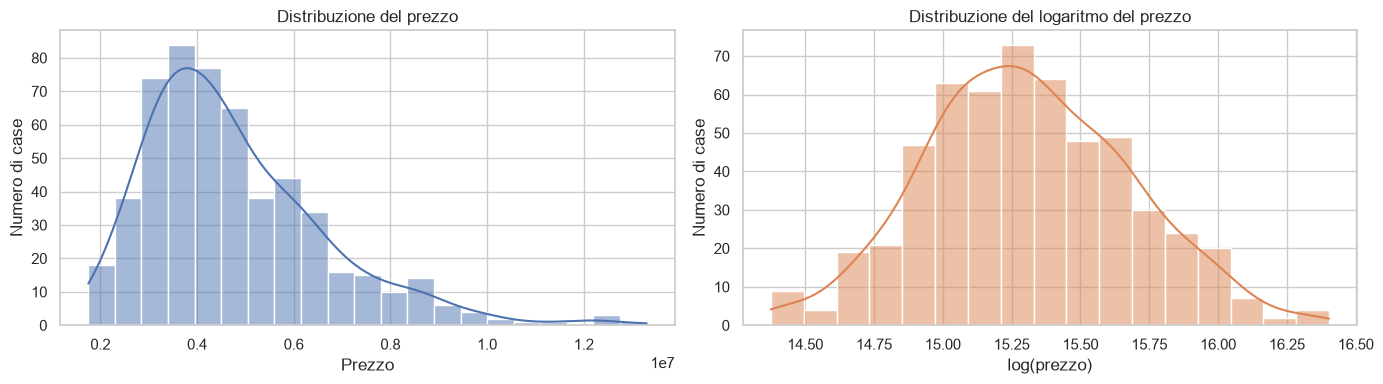

Asimmetria (skewness) prezzo: 1.21 | log(prezzo): 0.14


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0])
axes[0].set(title="Distribuzione del prezzo", xlabel="Prezzo", ylabel="Numero di case")
sns.histplot(np.log(df[TARGET]), kde=True, ax=axes[1], color="#dd8452")
axes[1].set(title="Distribuzione del logaritmo del prezzo", xlabel="log(prezzo)", ylabel="Numero di case")
fig.tight_layout()
plt.show()
print(f"Asimmetria (skewness) prezzo: {df[TARGET].skew():.2f} | log(prezzo): {np.log(df[TARGET]).skew():.2f}")

**Cosa osserviamo** – Il prezzo è **asimmetrico** (asimmetria 1,21): la maggior parte delle case
costa tra 3 e 6 milioni, ma una coda di case molto costose arriva a 13 milioni. Il logaritmo
rende la distribuzione quasi simmetrica (asimmetria 0,14): lo useremo come alternativa nella sezione 8.

### 4.3 Le feature numeriche e categoriche

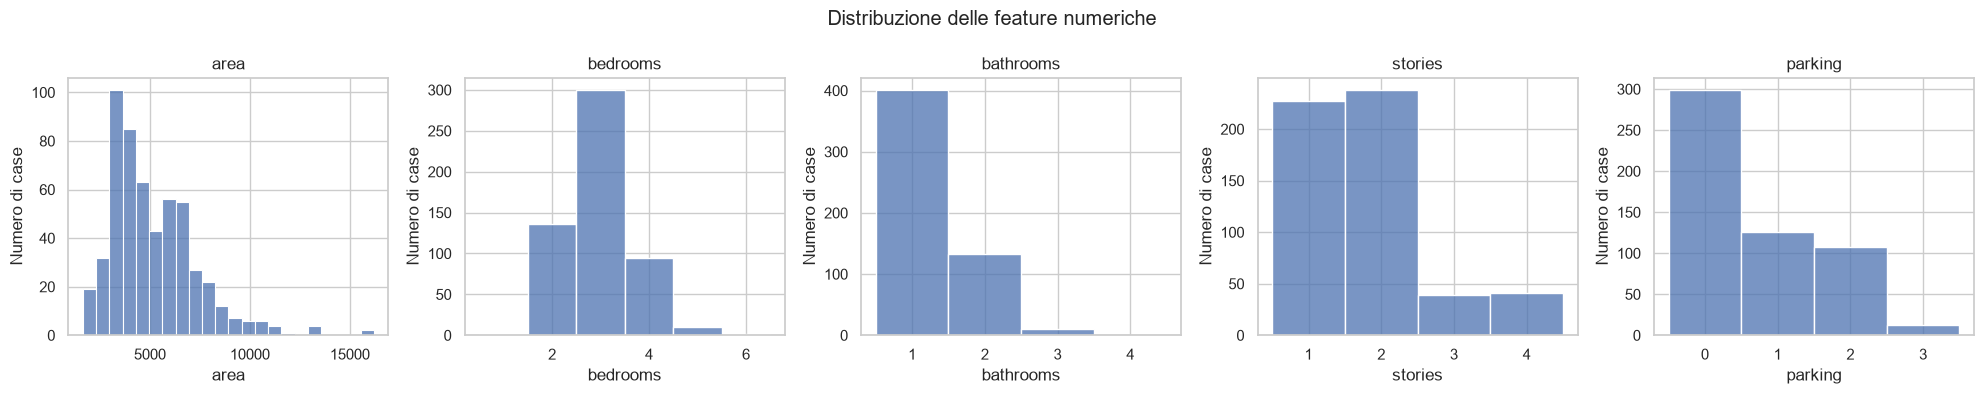

In [10]:
fig, axes = plt.subplots(1, len(NUMERIC_COLS), figsize=(20, 4))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(df[col], ax=ax, discrete=col != "area")
    ax.set(title=col, xlabel=col, ylabel="Numero di case")
fig.suptitle("Distribuzione delle feature numeriche")
fig.tight_layout()
plt.show()

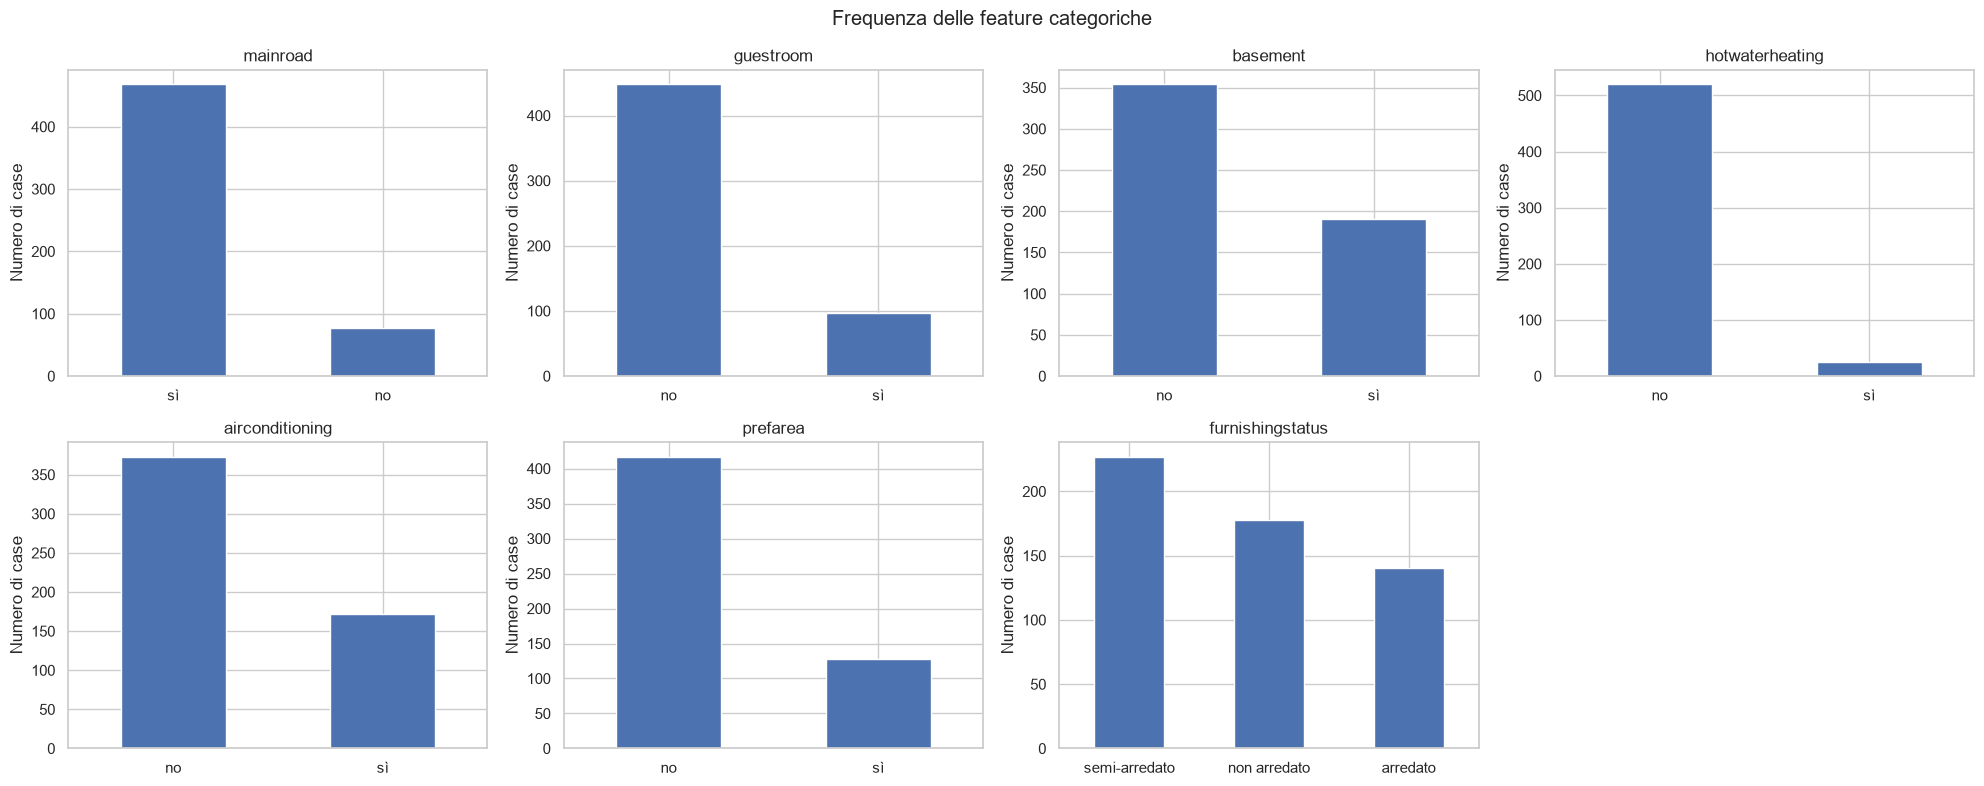

In [11]:
categoriche = BINARY_COLS + [FURNISH_COL]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, categoriche):
    etichette = df[col].map(FURNISH_ETICHETTE) if col == FURNISH_COL else df[col].map({0: "no", 1: "sì"})
    etichette.value_counts().plot.bar(ax=ax, color="#4c72b0")
    ax.set(title=col, xlabel="", ylabel="Numero di case")
    ax.tick_params(axis="x", rotation=0)
axes.flat[-1].axis("off")
fig.suptitle("Frequenza delle feature categoriche")
fig.tight_layout()
plt.show()

**Cosa osserviamo** – Anche l'area è asimmetrica a destra, con poche case oltre 10.000 unità di superficie. Le altre
numeriche hanno pochi valori: quasi tutte le case hanno 2–4 camere e 1–2 bagni, e più della metà non ha
posto auto. Tra le categoriche, `hotwaterheating` è **rara** (25 case su 545, il 4,6%): il suo effetto
sarà stimato con poca precisione. `mainroad` è al contrario quasi sempre presente (86% delle case).

### 4.4 Matrice di correlazione
Per `furnishingstatus` usiamo la codifica nell'ordine di Kaggle. Questo ordine infatti ordina in modo crescente le case da non arredate a completamente arredate e, ipotizzando che la presenza dell'arredamento aumenti il valore della casa, calcolare la correlazione lineare rispetto al prezzo usando questo ordinamento ha più senso.

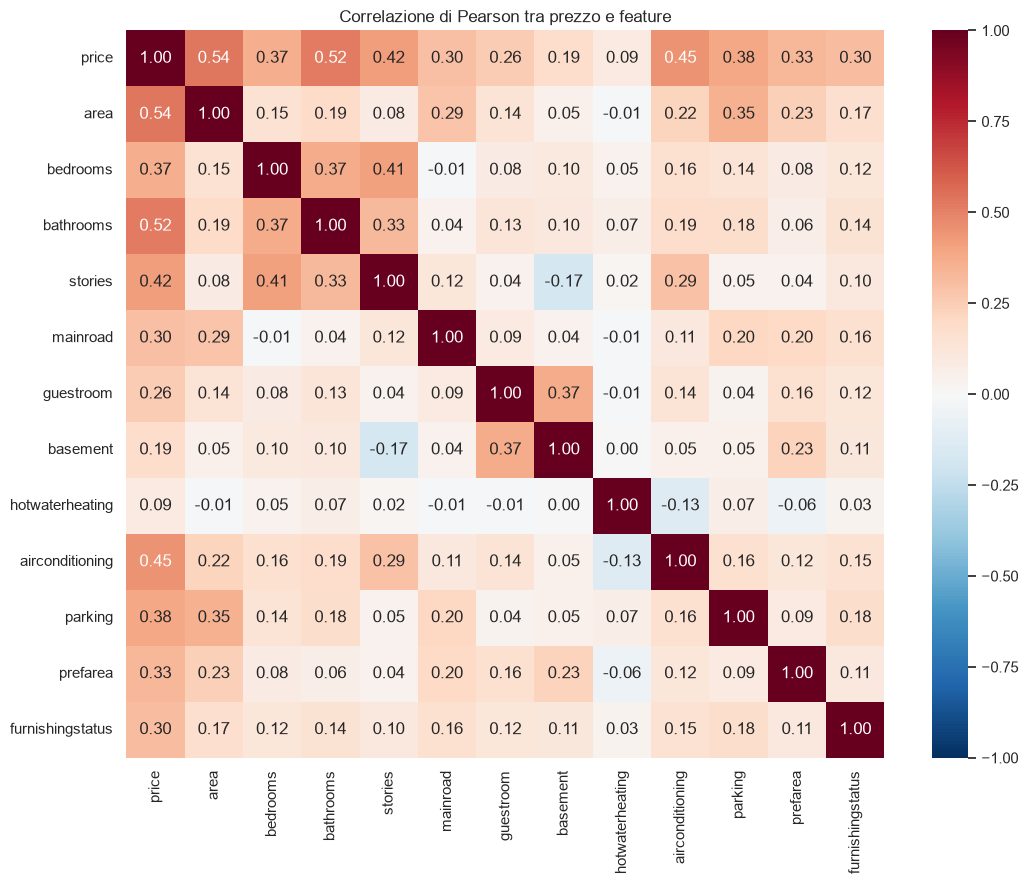

,correlazione con il prezzo
area,0.5360
bathrooms,0.5175
airconditioning,0.4530
stories,0.4207
parking,0.3844
bedrooms,0.3665
prefarea,0.3298
furnishingstatus,0.3047
mainroad,0.2969
guestroom,0.2555


In [12]:
corr = df.assign(**{FURNISH_COL: df[FURNISH_COL].map(FURNISH_CORRETTO)}).corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlazione di Pearson tra prezzo e feature")
fig.tight_layout()
plt.show()
corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("correlazione con il prezzo")

**Cosa osserviamo** – Le feature più legate al prezzo sono l'area (0,54), il numero di bagni (0,52),
l'aria condizionata (0,45) e il numero di piani (0,42); il riscaldamento ad acqua calda è quasi
scorrelato (0,09). Le correlazioni **tra** feature sono moderate (al massimo circa 0,4: camere–piani,
camere–bagni, guestroom–basement): non c'è una collinearità forte, quindi non ci aspettiamo coefficienti
molto instabili nella regressione lineare. È un primo indizio che la regolarizzazione potrebbe avere
poco margine di miglioramento.

### 4.5 Prezzo e area

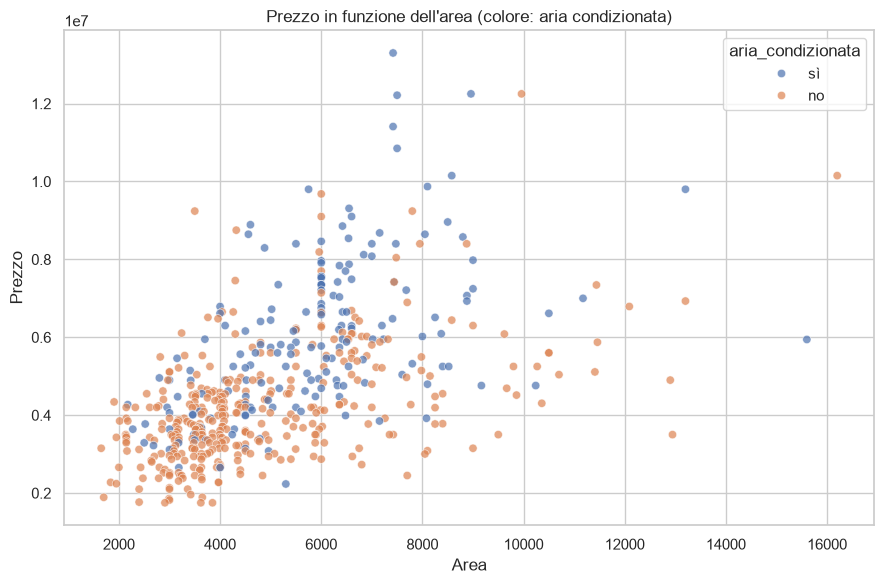

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df.assign(aria_condizionata=df["airconditioning"].map({0: "no", 1: "sì"})),
                x="area", y=TARGET, hue="aria_condizionata", alpha=0.7, ax=ax)
ax.set(title="Prezzo in funzione dell'area (colore: aria condizionata)", xlabel="Area", ylabel="Prezzo")
fig.tight_layout()
plt.show()

**Cosa osserviamo** – Il prezzo cresce con l'area, ma con molta dispersione: a parità di superficie i prezzi
variano anche del doppio, e la dispersione aumenta per le case più grandi e costose. Le case con aria
condizionata (blu) stanno in media più in alto. Questa dispersione è il limite principale di qualsiasi
modello che usi solo queste 12 caratteristiche.

### 4.6 Prezzo per categoria

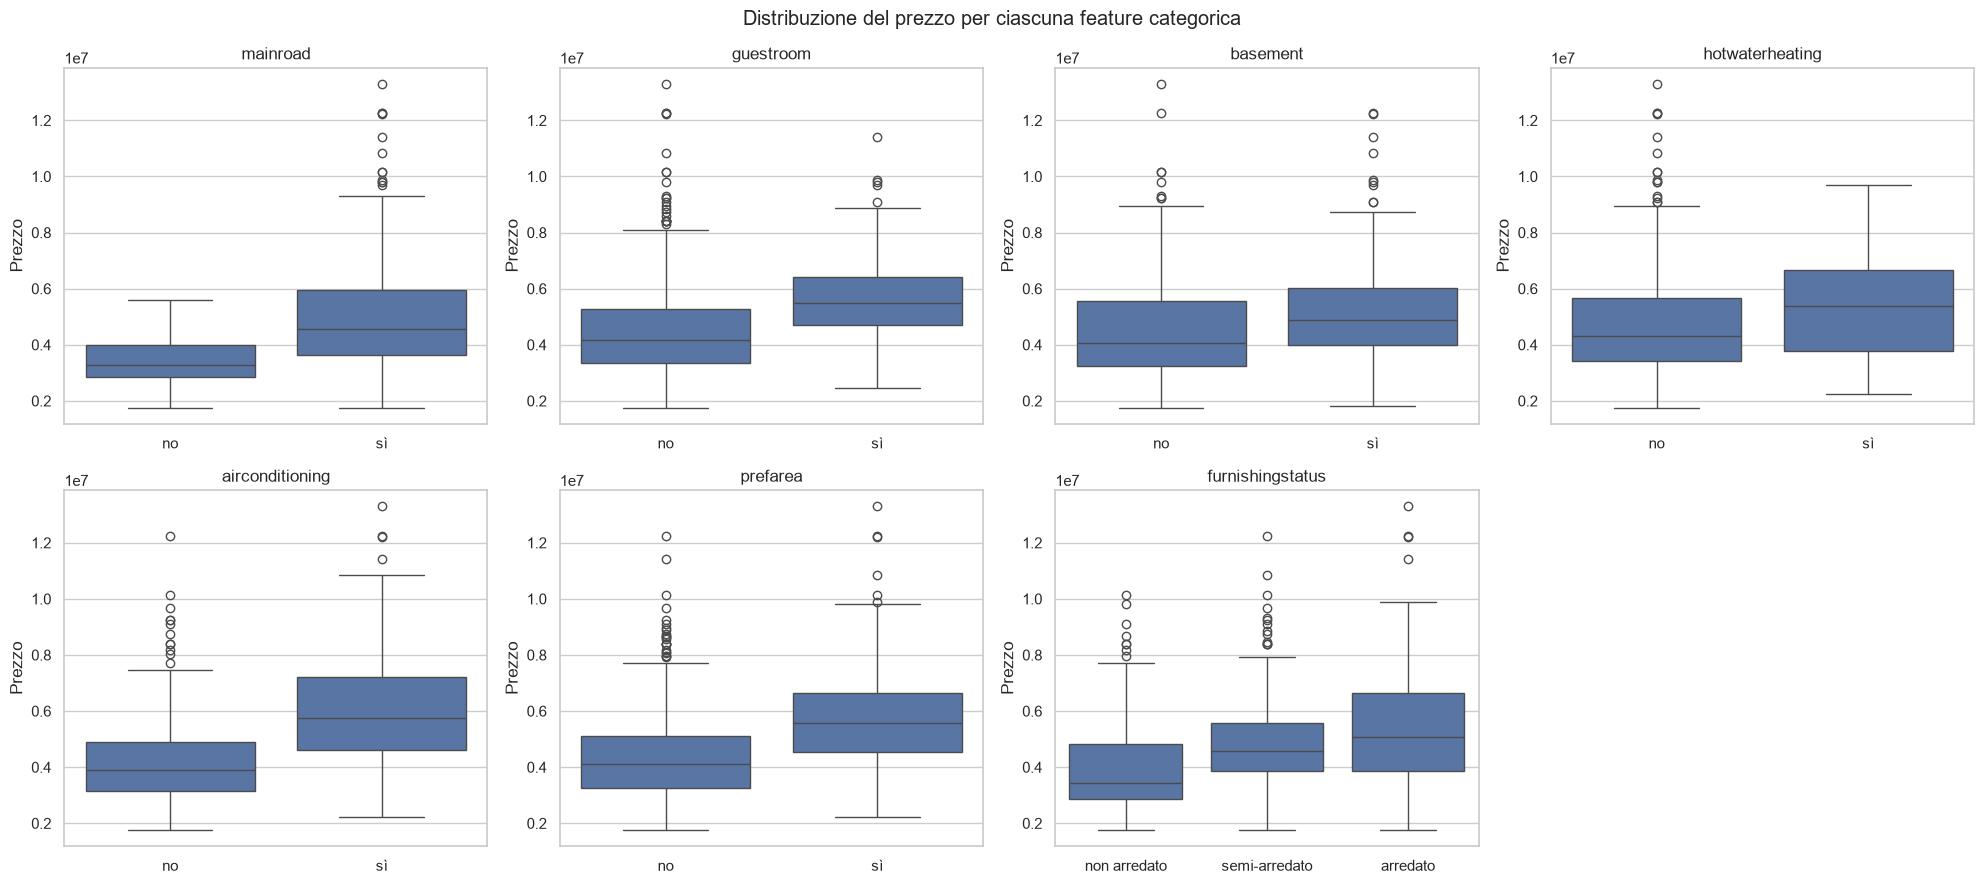

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, categoriche):
    if col == FURNISH_COL:
        etichette = df[col].map(FURNISH_ETICHETTE)
        ordine = ["non arredato", "semi-arredato", "arredato"]
    else:
        etichette = df[col].map({0: "no", 1: "sì"})
        ordine = ["no", "sì"]
    sns.boxplot(x=etichette, y=df[TARGET], order=ordine, ax=ax)
    ax.set(title=col, xlabel="", ylabel="Prezzo")
axes.flat[-1].axis("off")
fig.suptitle("Distribuzione del prezzo per ciascuna feature categorica")
fig.tight_layout()
plt.show()

**Cosa osserviamo** – Strada mainroad, airconditioning, prefarea e guestroom spostano
nettamente verso l'alto la mediana del prezzo. Per `furnishingstatus` la mediana cresce in modo monotono
da non arredato a semi-arredato ad arredato, ma il salto più grande è tra non arredato e semi-arredato:
"semi" e "arredato" sono più vicini tra loro di quanto suggerisca una scala con passi uguali.

## 5. Split train/test e modello di riferimento (baseline)
### 5.1 Mettere da parte il test set
Separiamo subito il **20% delle case come test set**: non lo useremo per nessuna scelta, ma solo alla
fine (sezione 10) per misurare le prestazioni su case "mai viste". La divisione è stratificata per
fasce di prezzo, così anche le case più costose sono rappresentate in entrambe le parti.

In [15]:
X_train, X_test, y_train, y_test = split_stratificato(df)
print(f"Training: {len(X_train)} case | Test: {len(X_test)} case")
pd.DataFrame({"training": y_train.describe(), "test": y_test.describe()})

Training: 436 case | Test: 109 case


,training,test
count,436.0000,109.0000
mean,"4,773,300.3211","4,740,444.9541"
std,"1,859,790.6919","1,920,953.3770"
min,"1,750,000.0000","1,890,000.0000"
25%,"3,430,000.0000","3,500,000.0000"
50%,"4,392,500.0000","4,270,000.0000"
75%,"5,755,750.0000","5,740,000.0000"
max,"12,250,000.0000","13,300,000.0000"


### 5.2 Baseline: regressione lineare multipla
Addestriamo il modello attuale (regressione lineare senza regolarizzazione) e confrontiamo l'errore
sui dati di addestramento con quello su dati non visti. Per non "sprecare" il test set usiamo un
**set di validazione**: il 20% del training, messo da parte con lo stesso criterio stratificato.
Se l'errore su dati nuovi è molto più alto di quello in addestramento, il modello è in overfitting.
Usiamo la codifica ordinal di `furnishingstatus` con l'ordine corretto.

In [16]:
df_train = X_train.assign(**{TARGET: y_train})
X_fit, X_val, y_fit, y_val = split_stratificato(df_train)
baseline = costruisci_pipeline("ordinal_corretto", "Lineare").fit(X_fit, y_fit)
confronto_baseline = pd.DataFrame({
    "addestramento": metriche(y_fit, baseline.predict(X_fit)),
    "validazione": metriche(y_val, baseline.predict(X_val)),
})
confronto_baseline["rapporto validazione/addestramento"] = confronto_baseline["validazione"] / confronto_baseline["addestramento"]
confronto_baseline

,addestramento,validazione,rapporto validazione/addestramento
mse,"1,146,090,420,546.8618","1,023,764,775,566.5991",0.8933
rmse,"1,070,556.1268","1,011,812.6188",0.9451
mae,"782,204.9052","750,563.8219",0.9595
r2,0.6763,0.6685,0.9884


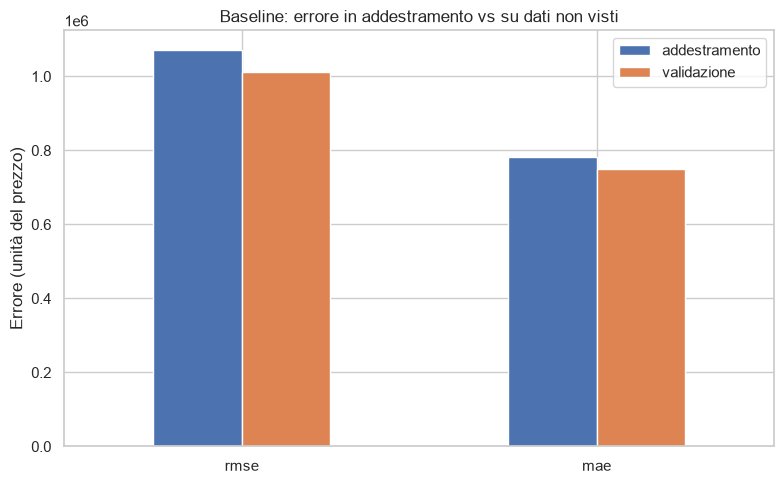

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
confronto_baseline.loc[["rmse", "mae"], ["addestramento", "validazione"]].plot.bar(ax=ax, color=["#4c72b0", "#dd8452"])
ax.set(title="Baseline: errore in addestramento vs su dati non visti", ylabel="Errore (unità del prezzo)", xlabel="")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

**Cosa osserviamo** – **Su questi dati la regressione lineare non è in overfitting.** L'errore su case
non viste (RMSE circa 1,01 milioni) è addirittura leggermente *più basso* di quello in addestramento
(1,07 milioni; rapporto 0,95) e l'R² è praticamente identico (0,68 in addestramento, 0,67 in validazione).
Con 545 case e solo 12 feature, la regressione lineare ha poche occasioni di "memorizzare" i dati. Il
problema segnalato dal team (stime meno precise sugli immobili nuovi) qui non si riproduce, almeno a
livello aggregato.

## 6. Modelli regolarizzati con due codifiche di `furnishingstatus`
La **regolarizzazione** aggiunge all'obiettivo del modello una penalità sulla grandezza dei coefficienti:
- **Ridge** (penalità L2) "rimpicciolisce" tutti i coefficienti, senza azzerarli: utile con feature correlate;
- **Lasso** (penalità L1) può praticamente azzerare i coefficienti meno utili: seleziona le feature;
- **Elastic Net** combina le due penalità (`l1_ratio` regola il mix).

La forza della penalità è `alpha`: con alpha = 0 si torna alla regressione lineare, con alpha molto grande
il modello predice sempre il prezzo medio. Per ciascuno dei 4 modelli e delle 2 codifiche della colonna `furnishingstatus` cerchiamo
l'alpha migliore con la cross-validation ripetuta: **8 configurazioni, stesso protocollo**.

Ricordiamo che le altre 11 feature sono identiche nelle due codifiche: le differenze possono venire solo da
`furnishingstatus`.

In [18]:
risultati_prezzo = [addestra_configurazione(X_train, y_train, encoding, nome) for encoding in ENCODINGS for nome in NOMI_MODELLI]
df_prezzo = tabella_risultati(risultati_prezzo)
df_prezzo

,encoding,modello,target,feature,rmse_mean,rmse_std,rmse_train,mse_mean,mae_mean,r2_mean,n_feature,n_coef_nonzero,best_params,alpha_al_bordo
0,onehot,ElasticNet,prezzo,originali,"1,093,386.6161","106,142.4923","1,049,666.5714","1,206,760,521,019.2280","793,937.6536",0.6426,13,13,"{'alpha': 8.858667904100825, 'l1_ratio': 0.99}",False
1,onehot,Ridge,prezzo,originali,"1,093,444.9671","106,092.8020","1,048,513.6836","1,206,877,578,644.6067","795,184.4424",0.6424,13,13,{'alpha': 22.122162910704503},False
2,ordinal_corretto,ElasticNet,prezzo,originali,"1,093,548.9503","106,872.7025","1,053,735.4078","1,207,271,081,156.1277","791,390.5925",0.6428,12,12,"{'alpha': 8.858667904100825, 'l1_ratio': 0.99}",False
3,ordinal_corretto,Ridge,prezzo,originali,"1,093,553.6782","106,914.7824","1,052,666.9148","1,207,290,417,868.8540","792,605.9783",0.6427,12,12,{'alpha': 22.122162910704503},False
4,ordinal_corretto,Lineare,prezzo,originali,"1,095,391.4001","107,216.8229","1,051,422.6073","1,211,377,766,610.0393","796,953.9142",0.6412,12,12,{},False
5,ordinal_corretto,Lasso,prezzo,originali,"1,095,391.4318","107,216.8809","1,051,422.6073","1,211,377,848,492.6155","796,953.7218",0.6412,12,12,{'alpha': 1.0},False
6,onehot,Lineare,prezzo,originali,"1,095,600.2516","106,045.9495","1,047,167.6545","1,211,585,654,671.9441","799,765.6011",0.6405,13,13,{},False
7,onehot,Lasso,prezzo,originali,"1,095,600.2673","106,046.0305","1,047,167.6545","1,211,585,706,368.1541","799,765.4014",0.6405,13,13,{'alpha': 1.0},False


**Una nota sull'MSE.** L'errore quadratico medio è nell'ordine di 10¹² perché si misura in
*unità di prezzo al quadrato*: un numero corretto ma poco leggibile. Per questo affianchiamo l'RMSE (la sua
radice, nella stessa unità del prezzo) e il MAE: dicono di quanto sbaglia, tipicamente, il modello su una casa.

**Cosa osserviamo** – Tutte le 8 configurazioni hanno praticamente lo **stesso errore**: RMSE medio tra
1,093 e 1,096 milioni (circa il 23% del prezzo medio di 4,77 M), MAE intorno a 0,79–0,80 M e R² di circa
0,64. La differenza tra la migliore e la peggiore (circa 2.200) è **quasi cinquanta volte più piccola**
della variabilità tra un fold e l'altro (deviazione standard di circa 106.000). Il Lasso sceglie sempre
l'alpha più piccolo provato (1,0): su un target nell'ordine dei milioni è una penalità nulla, e infatti i
suoi risultati coincidono con quelli della regressione lineare.

## 7. Confronto tra codifiche e modelli (prezzo originale)
### 7.1 Errore di cross-validation

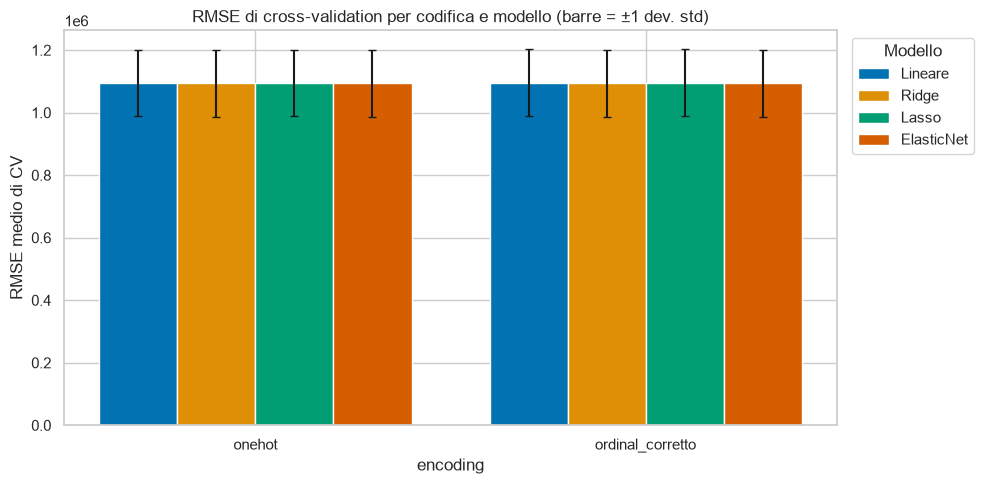

RMSE più basso sul prezzo: ElasticNet – prezzo – onehot (1,093,387 ± 106,142)


modello,Lineare,Ridge,Lasso,ElasticNet
encoding,,,,
ordinal_corretto,"1,095,391.4001","1,093,553.6782","1,095,391.4318","1,093,548.9503"
onehot,"1,095,600.2516","1,093,444.9671","1,095,600.2673","1,093,386.6161"


In [19]:
fig = grafico_barre_modelli(df_prezzo, "rmse_mean", "RMSE medio di CV",
                            "RMSE di cross-validation per codifica e modello (barre = ±1 dev. std)",
                            colonna_errore="rmse_std")
plt.show()
migliore_prezzo = scegli_migliore(df_prezzo)
print(f"RMSE più basso sul prezzo: {nome_configurazione(migliore_prezzo)} "
      f"({migliore_prezzo['rmse_mean']:,.0f} ± {migliore_prezzo['rmse_std']:,.0f})")
df_prezzo.pivot(index="encoding", columns="modello", values="rmse_mean")[NOMI_MODELLI].loc[ENCODINGS]

**Cosa osserviamo** – Le barre sono tutte alla stessa altezza e le barre di errore si sovrappongono
quasi completamente: **né la codifica né il modello cambiano l'errore in modo misurabile**. L'RMSE più
basso è quello di Elastic Net con il one-hot (1,093 M ± 0,106 M), ma la configurazione peggiore dista solo
circa 2.200. `furnishingstatus` pesa poco rispetto ad area, bagni e piani (lo si vedeva già dalle
correlazioni con il prezzo), quindi il modo in cui lo codifichiamo si perde nella variabilità complessiva.

### 7.2 L'errore al variare di alpha
Per i grafici di questa sezione usiamo la codifica della configurazione con l'RMSE più basso sul prezzo: con
l'altra codifica le curve sono praticamente identiche.

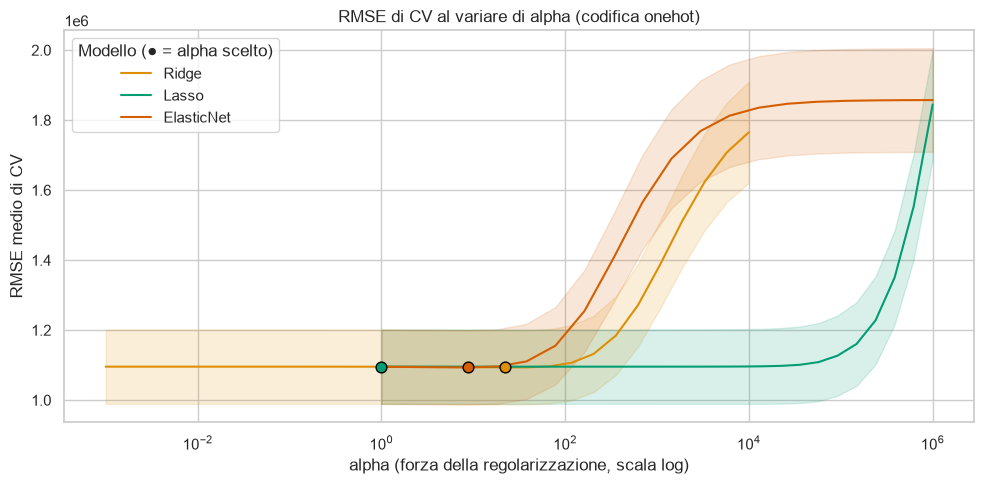

In [20]:
fig = grafico_errore_vs_alpha([r for r in risultati_prezzo if r["encoding"] == migliore_prezzo["encoding"]],
                              f"RMSE di CV al variare di alpha (codifica {migliore_prezzo['encoding']})")
plt.show()

**Cosa osserviamo** – Le curve sono **piatte a sinistra**: con penalità piccole tutti i modelli si
comportano come la regressione lineare. Poi salgono: troppa penalità schiaccia i coefficienti e l'errore
cresce fino a quello di un modello che predice sempre il prezzo medio (circa 1,85 M). Non c'è una "valle"
in cui la regolarizzazione migliori l'errore: gli alpha scelti (i punti) stanno tutti nella parte piatta.
Il Lasso tollera alpha molto più grandi di Ridge solo perché le due penalità sono su scale diverse.

### 7.3 Come il Lasso seleziona le feature

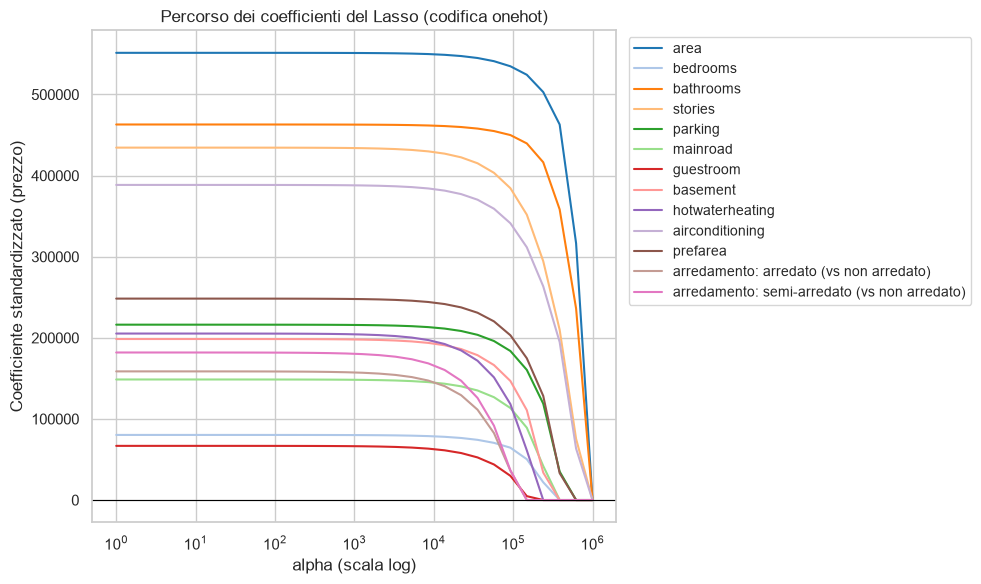

In [21]:
fig = grafico_percorso_lasso(X_train, y_train, migliore_prezzo["encoding"],
                             f"Percorso dei coefficienti del Lasso (codifica {migliore_prezzo['encoding']})")
plt.show()

**Cosa osserviamo** – Aumentando la penalità, le prime feature ad essere azzerate (alpha intorno a 10⁵)
sono `guestroom`, le due colonne dell'arredamento e `hotwaterheating`, seguite da `bedrooms`, `basement` e
`mainroad`. Quelle che resistono più a lungo sono **area, bagni, piani e aria condizionata**: sono le
caratteristiche che portano più informazione sul prezzo. Però tutte queste esclusioni avvengono con alpha
oltre 10⁴–10⁵, dove l'errore di validazione è già peggiorato (grafico 7.2): **all'alpha ottimo nessuna
feature viene eliminata**.

### 7.4 Quanti coefficienti restano diversi da zero

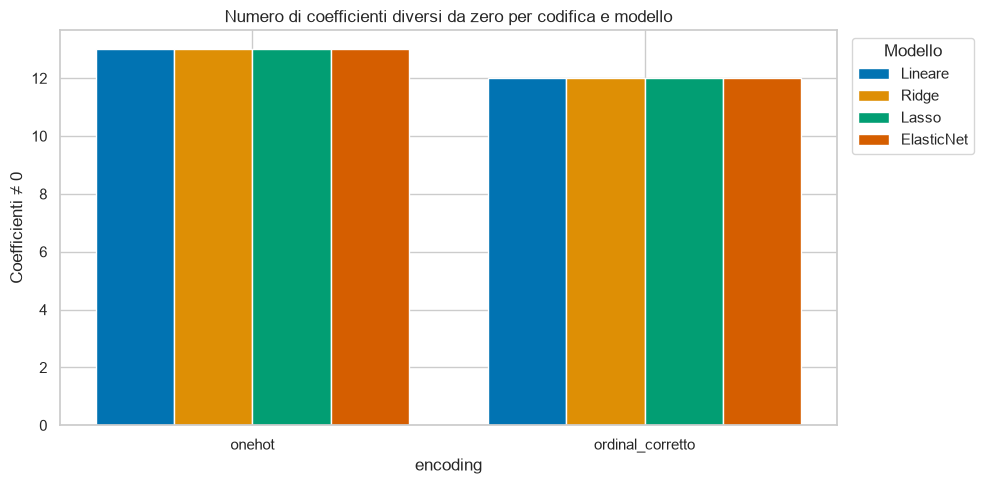

In [22]:
fig = grafico_barre_modelli(df_prezzo, "n_coef_nonzero", "Coefficienti ≠ 0",
                            "Numero di coefficienti diversi da zero per codifica e modello")
plt.show()

**Cosa osserviamo** – Tutti i modelli tengono **tutti i coefficienti diversi da zero** (12 con la codifica
ordinal, 13 con il one-hot, che ha una colonna in più seplicemente perchè utilizza 2 colonne per lo stato dell'arredamento invece ch una). Il Lasso, che potrebbe eliminare le feature
inutili, non ne elimina nessuna: secondo i dati ogni caratteristica contribuisce alla stima del prezzo.

### 7.5 Coefficienti a confronto: Ridge, Lasso, Elastic Net

In [23]:
coef_confronto = pd.concat({
    nome: tabella_effetti(trova_risultato(risultati_prezzo, migliore_prezzo["encoding"], nome, "prezzo")["search"].best_estimator_)
          .set_index("feature")["coef_std"]
    for nome in NOMI_MODELLI
}, axis=1).dropna()
coef_confronto

,Lineare,Ridge,Lasso,ElasticNet
feature,,,,
area,"551,377.7158","528,558.7464","551,377.5595","513,377.4861"
bathrooms,"463,017.9339","450,041.0596","463,017.7867","440,863.4030"
stories,"434,503.8870","414,592.1880","434,503.3143","401,784.0701"
airconditioning,"388,517.2927","378,289.4025","388,516.7962","370,899.0531"
prefarea,"248,349.0727","244,257.4852","248,348.5934","241,100.3918"
parking,"216,212.3523","216,731.3961","216,211.9766","216,660.9721"
hotwaterheating,"205,271.7646","194,311.6639","205,270.8443","186,845.9212"
basement,"198,519.5534","186,418.2890","198,518.9811","178,804.6115"
arredamento: semi-arredato (vs non arredato),"181,910.8216","169,478.7983","181,909.2400","161,370.5018"


**Cosa osserviamo** – Il Lasso, con alpha ottimo minimo, ha coefficienti **identici** alla regressione
lineare: non azzera nulla. Ridge ed Elastic Net riducono un po' i coefficienti maggiori (area, bagni, piani:
circa −3–8%) e aumentano leggermente quelli minori (camere, ospiti, strada principale): la penalità
"redistribuisce" il peso tra feature correlate, ma l'effetto è piccolo. In tutti i modelli la classifica è
la stessa: **area, bagni, piani e aria condizionata** sono le caratteristiche che pesano di più sul prezzo;
camere e stanza degli ospiti sono le meno rilevanti (a parità delle altre caratteristiche).

### 7.6 One-hot vs ordinal: cosa cambia nei coefficienti di `furnishingstatus`

In [24]:
pd.concat({
    encoding: tabella_effetti(trova_risultato(risultati_prezzo, encoding, "Lasso", "prezzo")["search"].best_estimator_)
              .set_index("feature").filter(regex="arred|furnish", axis=0)[["coef_std", "effetto_prezzo"]]
    for encoding in ENCODINGS
}).rename_axis(["codifica", "feature"])

coef_std  \
codifica         feature                                                     
ordinal_corretto furnishingstatus                             144,671.6407   
onehot           arredamento: semi-arredato (vs non arredato) 181,909.2400   
                 arredamento: arredato (vs non arredato)      158,619.4872   

                                                               effetto_prezzo  
codifica         feature                                                       
ordinal_corretto furnishingstatus                                192,183.3131  
onehot           arredamento: semi-arredato (vs non arredato)    367,553.6770  
                 arredamento: arredato (vs non arredato)         365,205.9867

**Cosa osserviamo** – Il one-hot mostra che **semi-arredato e arredato valgono quasi lo stesso** (circa
+368.000 e +365.000 rispetto a una casa non arredata). L'ordinal corretto invece impone due passi
uguali da circa 192.000: sottostima il primo salto e inventa il secondo. La differenza non cambia l'errore
complessivo, ma per **interpretare** l'effetto dell'arredamento il one-hot racconta la storia più fedele.

## 8. Passaggio al logaritmo del prezzo
Nella sezione 4 abbiamo visto che il prezzo è asimmetrico: poche case molto costose "tirano" il modello.
Addestrando sul **logaritmo del prezzo**:
- la distribuzione diventa più simmetrica;
- gli effetti diventano **percentuali** (es. "l'aria condizionata aumenta il prezzo del X%") invece che
  in valore assoluto fisso. 

Proviamo il logaritmo con **entrambe le codifiche e tutti e 4 i modelli**: altre 8 configurazioni, con
lo stesso protocollo della sezione 6. Le predizioni vengono riconvertite sulla scala del prezzo prima di calcolare le metriche, quindi i numeri sono
**direttamente confrontabili** con la sezione 6.

In [25]:
risultati_log = [addestra_configurazione(X_train, y_train, encoding, nome, log_target=True)
                 for encoding in ENCODINGS for nome in NOMI_MODELLI]
df_log = tabella_risultati(risultati_log)
df_log

,encoding,modello,target,feature,rmse_mean,rmse_std,rmse_train,mse_mean,mae_mean,r2_mean,n_feature,n_coef_nonzero,best_params,alpha_al_bordo
0,onehot,Ridge,log(prezzo),originali,"1,073,779.0904","115,809.6360","1,033,879.2757","1,166,413,406,887.9441","767,903.3980",0.6540,13,13,{'alpha': 22.122162910704503},False
1,onehot,ElasticNet,log(prezzo),originali,"1,075,082.1978","116,523.7995","1,032,002.7012","1,169,379,527,924.5713","770,842.3160",0.6529,13,13,"{'alpha': 0.007847599703514606, 'l1_ratio': 0.1}",False
2,onehot,Lineare,log(prezzo),originali,"1,075,263.2230","116,240.4080","1,031,694.4970","1,169,702,831,213.6609","771,863.5033",0.6526,13,13,{},False
3,onehot,Lasso,log(prezzo),originali,"1,075,264.2912","116,244.6352","1,031,696.2171","1,169,706,111,224.8511","771,857.1834",0.6526,13,13,{'alpha': 1e-05},False
4,ordinal_corretto,Ridge,log(prezzo),originali,"1,076,007.8049","116,231.4631","1,038,103.5830","1,171,302,549,240.8240","771,709.0018",0.6525,12,12,{'alpha': 12.689610031679234},False
5,ordinal_corretto,Lineare,log(prezzo),originali,"1,076,650.5731","116,394.9394","1,036,769.1417","1,172,724,238,480.6921","774,401.5835",0.6520,12,12,{},False
6,ordinal_corretto,ElasticNet,log(prezzo),originali,"1,076,650.6700","116,395.4068","1,036,769.7882","1,172,724,555,951.7881","774,399.7884",0.6520,12,12,"{'alpha': 1e-05, 'l1_ratio': 0.1}",False
7,ordinal_corretto,Lasso,log(prezzo),originali,"1,076,655.0188","116,399.8944","1,036,773.7724","1,172,734,964,985.7539","774,391.9277",0.6520,12,12,{'alpha': 1e-05},False


**Cosa osserviamo** – Sul logaritmo l'RMSE scende a 1,074–1,077 milioni (contro 1,093–1,096 M sul prezzo
originale) e il MAE a circa 0,77 M (contro 0,79–0,80 M): un miglioramento di circa il 2% sull'RMSE e il 3%
sul MAE, con entrambe le codifiche e il one-hot leggermente davanti. È però **molto più piccolo di una
deviazione standard** (circa 116.000). Anche qui Lasso ed Elastic Net scelgono penalità minime e coincidono
di fatto con la regressione lineare; solo Ridge applica una penalità vera, con un vantaggio trascurabile
(circa 1.500 rispetto alla Lineare).

## 9. Prezzo originale vs logaritmo e scelta del modello finale
### 9.1 Metriche
Mettiamo insieme le 16 configurazioni (8 sul prezzo e 8 sul logaritmo). Nel grafico ogni gruppo di barre
è una combinazione di target e codifica.

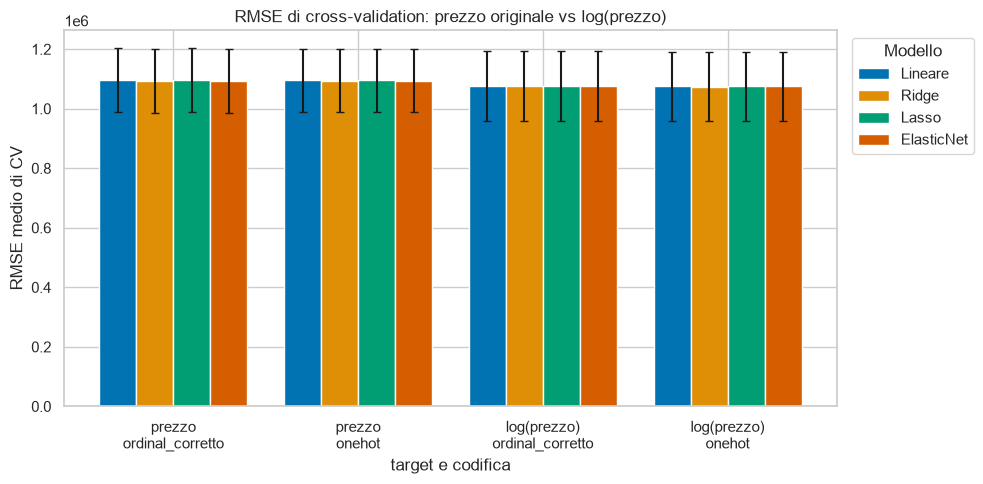

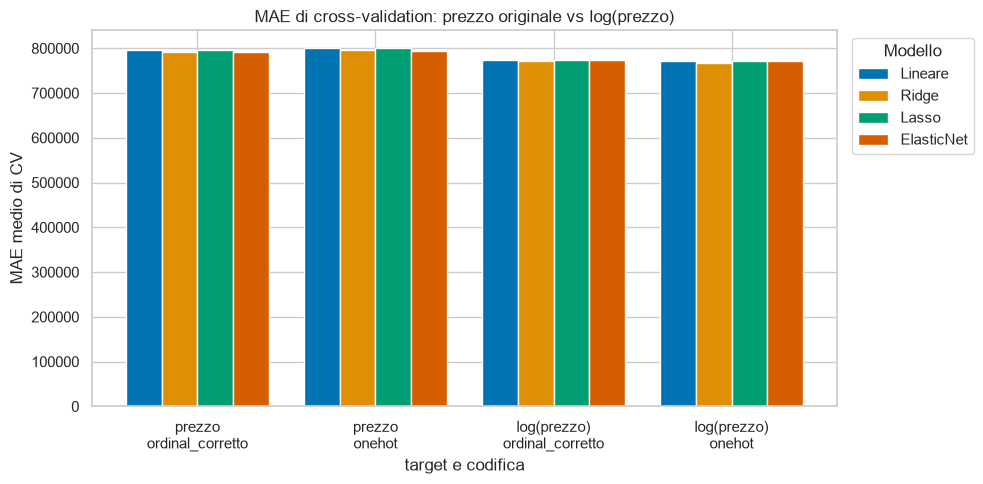

,target,encoding,modello,rmse_mean,rmse_std,mae_mean,r2_mean,n_coef_nonzero
0,log(prezzo),onehot,Ridge,"1,073,779.0904","115,809.6360","767,903.3980",0.6540,13
1,log(prezzo),onehot,ElasticNet,"1,075,082.1978","116,523.7995","770,842.3160",0.6529,13
2,log(prezzo),onehot,Lineare,"1,075,263.2230","116,240.4080","771,863.5033",0.6526,13
3,log(prezzo),onehot,Lasso,"1,075,264.2912","116,244.6352","771,857.1834",0.6526,13
4,log(prezzo),ordinal_corretto,Ridge,"1,076,007.8049","116,231.4631","771,709.0018",0.6525,12
5,log(prezzo),ordinal_corretto,Lineare,"1,076,650.5731","116,394.9394","774,401.5835",0.6520,12
6,log(prezzo),ordinal_corretto,ElasticNet,"1,076,650.6700","116,395.4068","774,399.7884",0.6520,12
7,log(prezzo),ordinal_corretto,Lasso,"1,076,655.0188","116,399.8944","774,391.9277",0.6520,12
8,prezzo,onehot,ElasticNet,"1,093,386.6161","106,142.4923","793,937.6536",0.6426,13
9,prezzo,onehot,Ridge,"1,093,444.9671","106,092.8020","795,184.4424",0.6424,13


In [26]:
df_tutti = tabella_risultati(risultati_prezzo + risultati_log)
ordine_gruppi = [f"{target}\n{encoding}" for target in TARGETS for encoding in ENCODINGS]
df_grafico = (df_tutti.assign(gruppo=df_tutti["target"] + "\n" + df_tutti["encoding"])
              .set_index("gruppo").loc[ordine_gruppi].reset_index())
fig = grafico_barre_modelli(df_grafico, "rmse_mean", "RMSE medio di CV",
                            "RMSE di cross-validation: prezzo originale vs log(prezzo)", x="gruppo",
                            colonna_errore="rmse_std")
fig.axes[0].set_xlabel("target e codifica")
plt.show()
fig = grafico_barre_modelli(df_grafico, "mae_mean", "MAE medio di CV",
                            "MAE di cross-validation: prezzo originale vs log(prezzo)", x="gruppo")
fig.axes[0].set_xlabel("target e codifica")
plt.show()
df_tutti[["target", "encoding", "modello", "rmse_mean", "rmse_std", "mae_mean", "r2_mean", "n_coef_nonzero"]]

**Cosa osserviamo** – Con il logaritmo tutte le barre si abbassano di poco (RMSE circa −20.000, MAE circa
−25.000), ma le barre di errore dei due target si sovrappongono quasi del tutto: il vantaggio è costante in
media, ma piccolo rispetto alla variabilità tra fold.

### 9.2 Residui: il log riduce gli errori sistematici sulle case costose?
Per ciascun target prendiamo la configurazione con l'RMSE più basso. Per guardare i residui senza toccare il
test set usiamo predizioni **fuori campione** sul training: ogni casa è predetta da un modello addestrato
senza di lei.

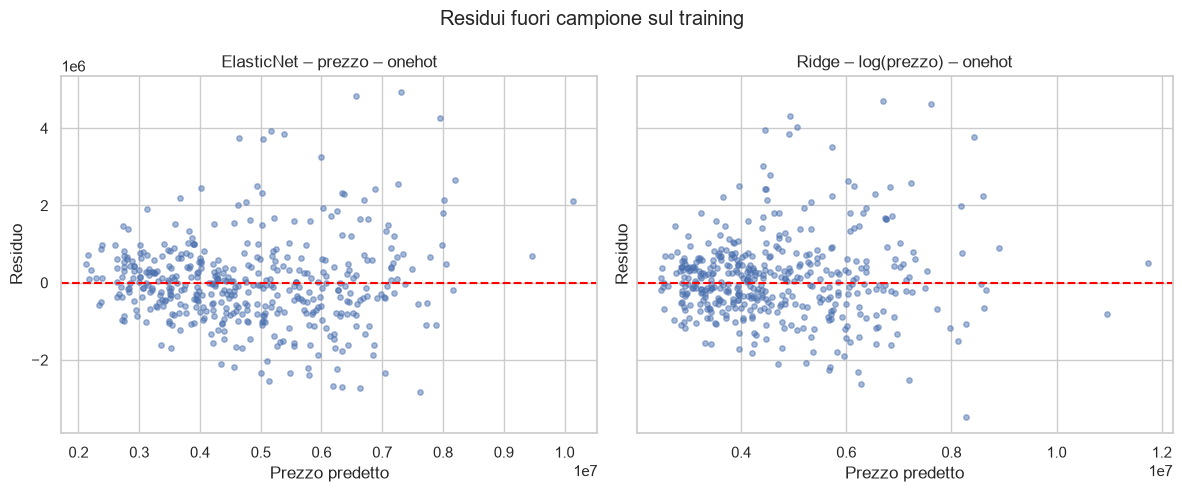

prezzo                               log(prezzo)  \
                              n  residuo_medio            mae           n   
fascia                                                                      
(1749999.999, 3290000.0]     92  -567,902.2949   704,699.1453          92   
(3290000.0, 3990000.0]       83  -343,185.0674   707,553.2686          83   
(3990000.0, 4830000.0]       89  -211,542.4122   639,457.0552          89   
(4830000.0, 6090000.0]       85   -29,688.4423   618,188.1812          85   
(6090000.0, 12250000.0]      87 1,127,008.1291 1,287,596.0144          87   

                                                        
                          residuo_medio            mae  
fascia                                                  
(1749999.999, 3290000.0]  -550,883.8954   628,945.8145  
(3290000.0, 3990000.0]    -222,051.0953   573,480.7512  
(3990000.0, 4830000.0]     -25,055.7243   605,551.5203  
(4830000.0, 6090000.0]     166,933.6589   656,590.7874  
(6090000.0, 12250000.0]  1,194,262.1194 1,375,960.5526

In [27]:
risultati_tutti = risultati_prezzo + risultati_log
scelta_prezzo = scegli_migliore(df_tutti[df_tutti["target"] == "prezzo"])
scelta_log = scegli_migliore(df_tutti[df_tutti["target"] == "log(prezzo)"])
stimatore_prezzo = trova_risultato(risultati_tutti, scelta_prezzo["encoding"], scelta_prezzo["modello"],
                                   "prezzo")["search"].best_estimator_
stimatore_log = trova_risultato(risultati_tutti, scelta_log["encoding"], scelta_log["modello"],
                                "log(prezzo)")["search"].best_estimator_
oof_prezzo = predizioni_oof(stimatore_prezzo, X_train, y_train)
oof_log = predizioni_oof(stimatore_log, X_train, y_train)

fig = grafico_residui_vs_predetti({nome_configurazione(scelta_prezzo): (y_train, oof_prezzo),
                                   nome_configurazione(scelta_log): (y_train, oof_log)},
                                  "Residui fuori campione sul training")
plt.show()
pd.concat({"prezzo": errore_per_fascia(y_train, oof_prezzo).set_index("fascia"),
           "log(prezzo)": errore_per_fascia(y_train, oof_log).set_index("fascia")}, axis=1)

**Cosa osserviamo** – In entrambi gli approcci (Elastic Net sul prezzo e Ridge sul log, entrambi con il
one-hot) la nuvola dei residui si allarga per i prezzi più alti, e la tabella per fasce mostra un **errore
sistematico**: le case più economiche sono sovrastimate (circa −0,55 M di residuo medio) e quelle più
costose **sottostimate di oltre 1 milione** in media (1,13 M sul prezzo, 1,19 M sul log). Il logaritmo
riduce gli errori nelle fasce basse e centrali (MAE da circa 0,71 a 0,57 M nella seconda fascia), ma li
aumenta leggermente nelle due fasce più alte e non risolve la sottostima delle case di lusso. Il modello
lineare "comprime" i prezzi verso la media: probabilmente mancano informazioni (posizione precisa, qualità,
età) che spiegano i prezzi estremi.

### 9.3 Scelta del modello finale (sul solo training)
Il modello finale è semplicemente la configurazione con l'RMSE medio più basso tra tutte le 16. La tabella
mostra le prime cinque, con la distanza dalla migliore confrontata con la deviazione standard.

In [28]:
scelta_finale = scegli_migliore(df_tutti)
print(f"Configurazione finale: {nome_configurazione(scelta_finale)}, parametri {scelta_finale['best_params']}")
(df_tutti.assign(distanza_dalla_migliore=df_tutti["rmse_mean"] - scelta_finale["rmse_mean"])
 [["modello", "target", "encoding", "rmse_mean", "rmse_std", "distanza_dalla_migliore", "mae_mean", "best_params"]]
 .head(5))

Configurazione finale: Ridge – log(prezzo) – onehot, parametri {'alpha': np.float64(22.122162910704503)}


,modello,target,encoding,rmse_mean,rmse_std,distanza_dalla_migliore,mae_mean,best_params
0,Ridge,log(prezzo),onehot,"1,073,779.0904","115,809.6360",0.0000,"767,903.3980",{'alpha': 22.122162910704503}
1,ElasticNet,log(prezzo),onehot,"1,075,082.1978","116,523.7995","1,303.1074","770,842.3160","{'alpha': 0.007847599703514606, 'l1_ratio': 0.1}"
2,Lineare,log(prezzo),onehot,"1,075,263.2230","116,240.4080","1,484.1326","771,863.5033",{}
3,Lasso,log(prezzo),onehot,"1,075,264.2912","116,244.6352","1,485.2008","771,857.1834",{'alpha': 1e-05}
4,Ridge,log(prezzo),ordinal_corretto,"1,076,007.8049","116,231.4631","2,228.7145","771,709.0018",{'alpha': 12.689610031679234}


**Cosa osserviamo** – L'RMSE più basso è quello di **Ridge sul logaritmo del prezzo con il one-hot**
(1,074 M ± 0,116 M, alpha ≈ 22): è il modello finale. La vittoria però è di misura: le altre quattro
configurazioni in tabella distano tra 1.300 e 2.200, e anche la peggiore delle 16 (Lasso sul prezzo con il
one-hot) dista circa 22.000, meno di un quinto della deviazione standard. Con altri fold la classifica
potrebbe cambiare. Inoltre la penalità scelta è leggera: il Ridge vincente fa quasi esattamente quello che
fa la regressione lineare sul log (1,075 M).

## 10. Valutazione finale sul test set
Ora, e solo ora, usiamo il test set. Valutiamo i due finalisti (la configurazione con l'RMSE più basso sul prezzo e quella sul log) e, come
riferimento, la regressione lineare non regolarizzata (il modello attuale), riaddestrata su tutto il training.
Le scelte sono già state fatte: questi numeri servono a stimare come si comporterà il modello su case nuove.

In [29]:
baseline_finale = costruisci_pipeline("ordinal_corretto", "Lineare").fit(X_train, y_train)
finalisti = {
    "Lineare (baseline) – prezzo – ordinal_corretto": baseline_finale,
    nome_configurazione(scelta_prezzo): stimatore_prezzo,
    nome_configurazione(scelta_log): stimatore_log,
}
risultati_test = pd.DataFrame({nome: metriche(y_test, est.predict(X_test)) for nome, est in finalisti.items()}).T
risultati_test["rmse CV (training)"] = [
    trova_risultato(risultati_tutti, "ordinal_corretto", "Lineare", "prezzo")["rmse_mean"],
    scelta_prezzo["rmse_mean"], scelta_log["rmse_mean"]]
risultati_test

,mse,rmse,mae,r2,rmse CV (training)
Lineare (baseline) – prezzo – ordinal_corretto,"1,147,285,988,287.2747","1,071,114.3675","799,627.3472",0.6862,"1,095,391.4001"
ElasticNet – prezzo – onehot,"1,150,773,025,162.3916","1,072,740.8938","792,600.1769",0.6853,"1,093,386.6161"
Ridge – log(prezzo) – onehot,"1,164,915,231,721.2131","1,079,312.3884","778,787.6413",0.6814,"1,073,779.0904"


**Cosa osserviamo** – Sul test set i tre modelli hanno RMSE tra 1,071 e 1,079 milioni e R² tra 0,68 e 0,69,
coerenti con le stime di cross-validation (1,07–1,10 M): la CV era affidabile e non ci sono sorprese su case
mai viste. L'RMSE più basso sul test è proprio quello della **regressione lineare di riferimento** (1,071 M),
mentre il Ridge sul log ha il MAE migliore (0,779 M contro 0,793–0,800 M) ma l'RMSE più alto: anche sul test
nessuna variante si distingue in modo netto.

### 10.1 Learning curve

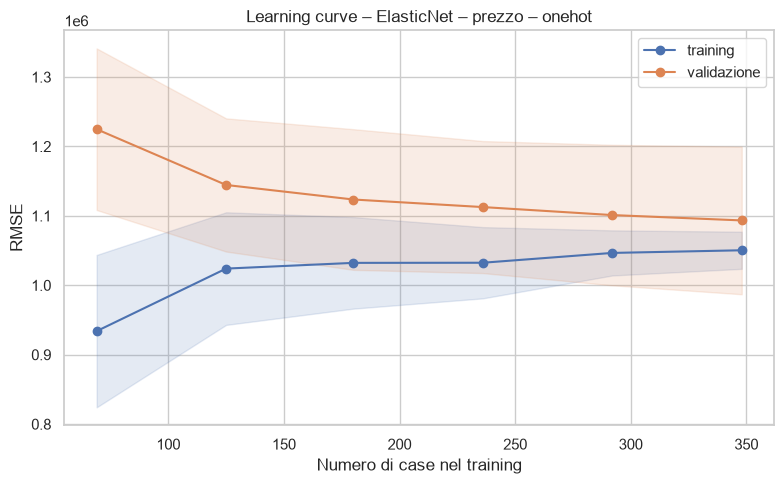

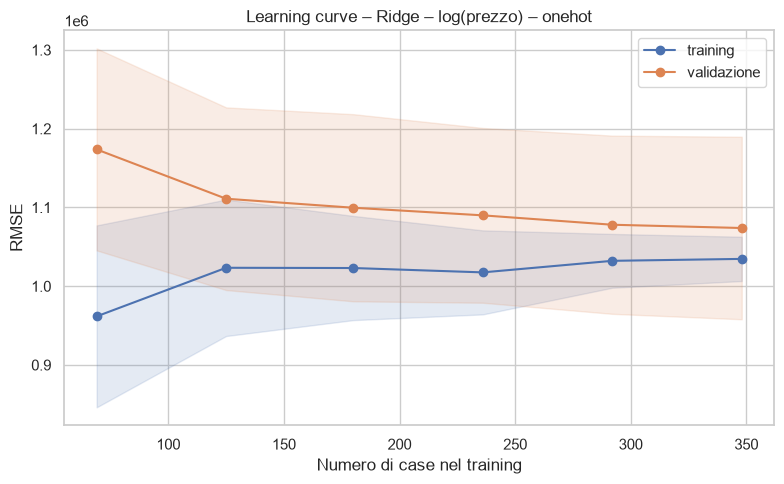

In [30]:
for nome in list(finalisti)[1:]:
    fig = grafico_learning_curve(finalisti[nome], X_train, y_train, f"Learning curve – {nome}")
    plt.show()

**Cosa osserviamo** – In entrambi i modelli le curve di training e validazione **convergono** a un errore
simile (con tutto il training, circa 1,05 e 1,09 milioni per Elastic Net sul prezzo, 1,03 e 1,07 per Ridge
sul log) con un divario piccolo e in calo. È il segno di un modello **non in overfitting**, ma limitato nella
capacità di spiegare il prezzo (*underfitting* lieve): aggiungere altre case con le stesse 12
caratteristiche migliorerebbe poco. Per ridurre l'errore servono **informazioni nuove** sugli immobili, non
un modello più vincolato.

### 10.2 Residui del modello finale sul test set

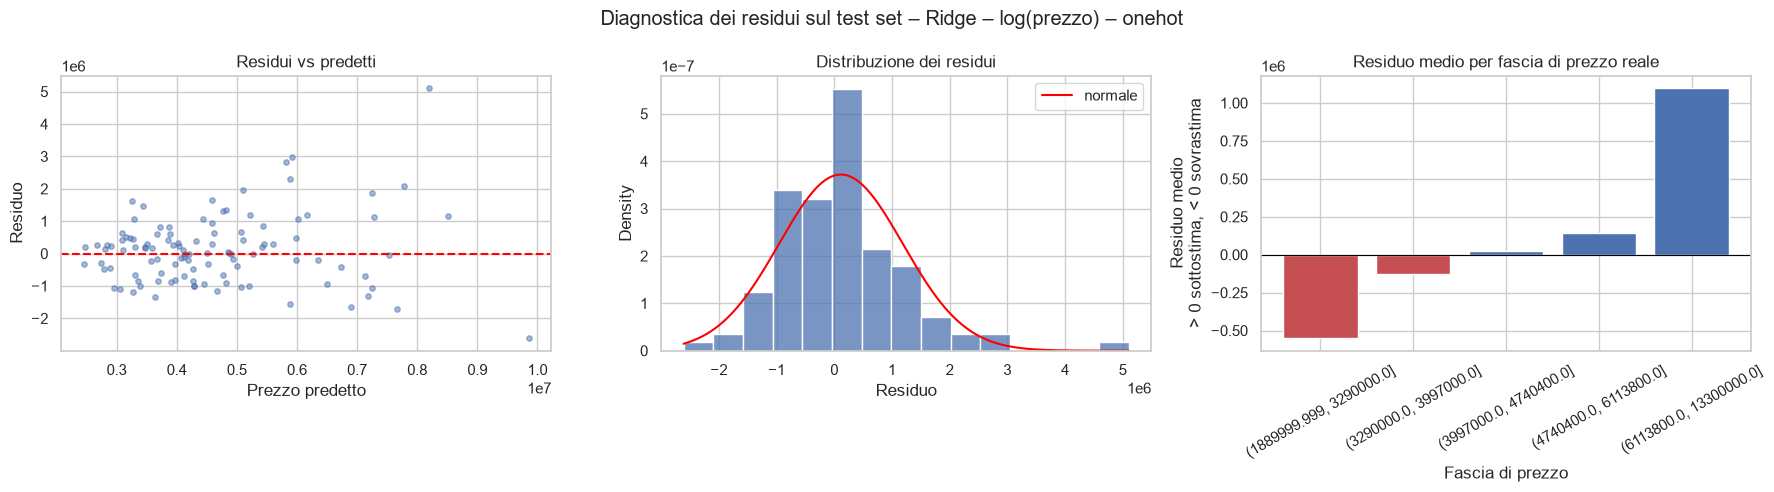

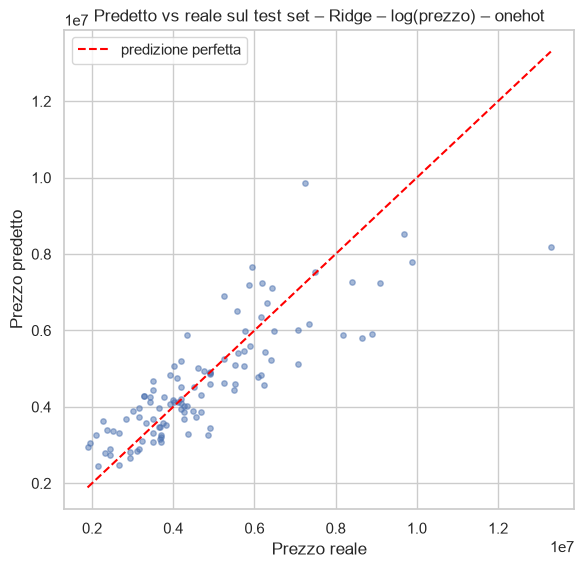

,fascia,n,residuo_medio,mae
0,"(1889999.999, 3290000.0]",23,"-550,370.2397","657,584.3246"
1,"(3290000.0, 3997000.0]",21,"-124,548.3132","459,142.8264"
2,"(3997000.0, 4740400.0]",21,"24,359.9167","509,932.1405"
3,"(4740400.0, 6113800.0]",22,"146,115.6779","693,352.9219"
4,"(6113800.0, 13300000.0]",22,"1,097,311.5915","1,552,685.2202"


In [31]:
nome_finale = nome_configurazione(scelta_finale)
stimatore_finale = trova_risultato(risultati_tutti, scelta_finale["encoding"], scelta_finale["modello"],
                                   scelta_finale["target"])["search"].best_estimator_
y_pred_test = stimatore_finale.predict(X_test)
fig = grafico_residui(y_test, y_pred_test, f"Diagnostica dei residui sul test set – {nome_finale}")
plt.show()
fig = grafico_predetto_vs_reale(y_test, y_pred_test, f"Predetto vs reale sul test set – {nome_finale}")
plt.show()
errore_per_fascia(y_test, y_pred_test)

**Cosa osserviamo** – I residui del modello finale (Ridge sul log) sono centrati sullo zero e la
distribuzione è vicina a una normale, con una coda a destra (alcune case vendute molto più del previsto,
fino a +5 M). Il grafico per fasce conferma sul test quanto visto in training: **le case più costose (oltre
circa 6,1 M) sono sottostimate di circa 1,1 milioni in media**, quelle più economiche sovrastimate di circa
0,55 M. Per i clienti significa che nelle fasce estreme le valutazioni vanno lette con più cautela.

## 11. Conclusioni e raccomandazione
### 11.1 Cosa pesa sul prezzo

Effetti calcolati su una casa di prezzo mediano (4,392,500)


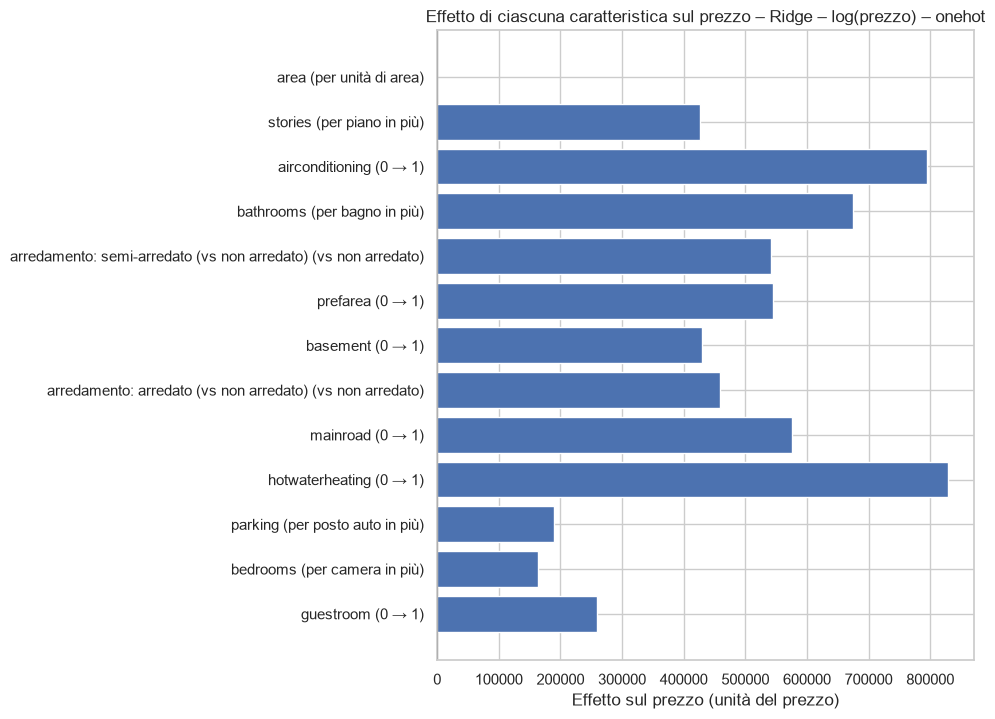

,feature,unita,coef_std,effetto_pct,effetto_prezzo
0,area,per unità di area,0.1041,0.0049,214.0439
1,stories,per piano in più,0.0818,9.7249,"427,166.3186"
2,airconditioning,0 → 1,0.0770,18.0922,"794,700.8409"
3,bathrooms,per bagno in più,0.0714,15.3712,"675,181.1682"
4,arredamento: semi-arredato (vs non arredato),vs non arredato,0.0575,12.3190,"541,110.9326"
5,prefarea,0 → 1,0.0495,12.4109,"545,147.9326"
6,basement,0 → 1,0.0445,9.7774,"429,471.2705"
7,arredamento: arredato (vs non arredato),vs non arredato,0.0431,10.4314,"458,200.3323"
8,mainroad,0 → 1,0.0427,13.0930,"575,109.6888"
9,hotwaterheating,0 → 1,0.0370,18.8846,"829,507.3599"


In [32]:
log_finale = scelta_finale["target"] == "log(prezzo)"
effetti = tabella_effetti(stimatore_finale, log_target=log_finale,
                          prezzo_riferimento=float(y_train.median()) if log_finale else None)
if log_finale:
    print(f"Effetti calcolati su una casa di prezzo mediano ({y_train.median():,.0f})")
fig = grafico_effetti(effetti, "effetto_prezzo", "Effetto sul prezzo (unità del prezzo)",
                      f"Effetto di ciascuna caratteristica sul prezzo – {nome_finale}")
plt.show()
effetti

### 11.2 Sintesi
- **Overfitting:** su questo dataset la regressione lineare multipla **non va in overfitting**: errore
  in addestramento e su dati nuovi sono praticamente uguali (RMSE circa 1,07 vs 1,01 M in hold-out; 1,10 M
  in CV contro 1,07 M sul test).
- **Regolarizzazione:** Ridge, Lasso ed Elastic Net non migliorano l'errore in modo misurabile: le
  differenze sono di qualche migliaio su una variabilità tra fold di oltre 100.000. Il Lasso sceglie una
  penalità nulla e **mantiene tutte le feature**: nessuna caratteristica è inutile.
- **Codifica di `furnishingstatus`:** il CSV ha i codici 1 e 2 invertiti rispetto alla documentazione. Le
  due codifiche danno lo stesso errore; il one-hot mostra che semi-arredato e arredato valgono quasi uguale
  (circa +365.000 rispetto a una casa non arredata).
- **Logaritmo del prezzo:** riduce leggermente l'errore in CV (circa −2% sull'RMSE, −3% sul MAE), entro la
  variabilità; non elimina la sottostima delle case più costose.
- **Modello finale:** Ridge sul log(prezzo) con il one-hot, scelto perché ha l'RMSE di CV più basso
  (1,074 M); sul test set RMSE 1,08 M, MAE 0,78 M, R² 0,68: spiega circa due terzi della variabilità dei prezzi.
- **Complicare il modello lineare non serve:** possiamo aggiungere penalità, combinarle, cambiare codifica o
  trasformare il target, ma alla fine **non otteniamo niente di meglio della regressione lineare semplice**:
  tutte le 16 varianti stanno entro un quinto di deviazione standard l'una dall'altra, e sul test set la
  regressione lineare di riferimento ha addirittura l'RMSE più basso.
- **Come si potrebbe fare meglio:** le learning curve (sezione 10.1) mostrano un *underfitting* lieve, cioè
  un modello che non riesce a spiegare tutta la variabilità dei prezzi. Le strade sono due:
  - **aggiungere feature**, la più promettente: posizione precisa, età, stato e qualità dell'immobile
    spiegano probabilmente buona parte dell'errore residuo, soprattutto sulle case più costose;
  - **provare modelli più complessi** (es. random forest o gradient boosting), capaci di cogliere effetti
    **non lineari** (soglie, curve, interazioni) che una regressione lineare non può descrivere. Il guadagno
    atteso però è limitato: le feature sono poche, il campione è piccolo (436 case di training) e i
    modelli ad alberi non prevedono prezzi più alti di quelli già visti, quindi da soli difficilmente
    risolvono la sottostima delle case di lusso.
- **Caratteristiche più influenti** (effetto a parità delle altre, in percentuale e, tra parentesi, su una
  casa di prezzo mediano, 4,39 M): **aria condizionata** +18% (circa +795.000); **un bagno in più** +15%
  (circa +675.000); **strada principale** +13%; **zona preferita** +12% (circa +545.000); **semi-arredato** e
  **arredato** +12% e +10% rispetto a non arredato; **un piano in più** +10% (circa +427.000); **area** circa
  +0,005% per unità di area (circa +214 per unità). Il riscaldamento ad acqua calda ha un effetto stimato alto
  (+19%), ma riguarda solo 25 case ed è quindi poco affidabile.

### 11.3 Raccomandazione operativa
- **Mantenere un modello lineare** nel motore di valutazione: su questi dati la regolarizzazione non porta
  vantaggi misurabili. Se si vuole una protezione "a costo zero" per quando si aggiungeranno feature,
  adottare **Ridge** con alpha scelto in cross-validation: ha lo stesso errore e stabilizza i
  coefficienti se in futuro compariranno feature correlate.
- **Correggere la codifica di `furnishingstatus`** nella documentazione e nella pipeline dei dati (1 =
  arredato, 2 = semi-arredato), preferendo il one-hot per leggere correttamente gli effetti.
- **Investire sui dati, non sul modello:** l'errore tipico (circa 1 milione, oltre il 20% del
  prezzo medio) dipende da informazioni che il dataset non contiene. Le priorità sono posizione precisa,
  età e stato dell'immobile, qualità delle finiture.
- **Segnalare ai clienti** che le stime sono meno affidabili nelle fasce estreme: le case di lusso
  tendono a essere sottovalutate (circa −1 M), quelle più economiche sopravvalutate.
- **Verificare il problema di partenza:** l'overfitting segnalato sugli immobili nuovi non emerge da
  questo campione. Conviene controllare se i nuovi immobili differiscono da quelli storici (zona, periodo,
  tipologia): uno spostamento nei dati, più che l'overfitting, spiegherebbe il calo di precisione.

### 11.4 Limiti
- **Campione piccolo e unità di misura non documentate:** 545 case; né il CSV né Kaggle indicano valuta
  e unità di area. Assumiamo che siano quelle in uso in azienda: se non lo fossero, le prestazioni non
  cambierebbero, ma coefficienti ed errori andrebbero riscalati prima di leggerli (sezione 4.1).
- **Poche caratteristiche:** mancano posizione precisa, età, stato e qualità dell'immobile, che spiegano
  buona parte della variabilità residua.
- **Stime di cross-validation leggermente ottimistiche:** alpha è scelto sulla stessa CV con cui si misura
  l'errore. Il test set finale, usato una sola volta, conferma però stime coerenti.
- **Effetti lineari e additivi:** il modello assume che, per esempio, un bagno in più valga lo stesso su
  una casa piccola e su una grande; il modello sul logaritmo (effetti percentuali) attenua questa ipotesi.
  Inoltre la riconversione dal logaritmo stima la mediana, non la media, del prezzo.
- **Approfondimenti possibili:** gestione degli outlier, feature derivate mirate (es. area per stanza),
  nested cross-validation e intervalli di previsione.